# TritFlow — balanced-ternary HDL to GDS

| Author | Affiliation | Email |
|---|---|---|
| Einosuke Okazaki (岡崎 英之介) | Information and Communication Engineering Course, Department of Monozukuri Engineering, Tokyo Metropolitan College of Industrial Technology (KOSEN), Tokyo, Japan | einosukeokazaki@gmail.com |

Fifth-year student (final year of the five-year KOSEN engineering programme, which combines upper-secondary and the first two years of tertiary education)
GitHub: [PenguinEino](https://github.com/PenguinEino).

Team: TritFlow. Representative: Einosuke Okazaki (岡崎 英之介).

**Apache-2.0.** The author of the historical balanced-ternary-logic project releases the derived schematic assets in this repository under Apache-2.0.

Ready for final submission review.

Recommended: Python 3.12; KLayout binary/Python 0.30.6; ngspice 42 (Ubuntu package 42+ds-3build1); OpenSUSI TR-1um `5d963db9d44e192d37a0489c208bfccf2e2f690c`. Use the Python packages installed by the notebook bootstrap; exact observed versions for each execution are in build-info.json.

# TritFlow：オープンソースPDK TR-1umで、三値のHDLからGDSへ

Einosuke Okazaki (岡崎 英之介)<br>
Information and Communication Engineering Course, Department of Monozukuri Engineering, Tokyo Metropolitan College of Industrial Technology (KOSEN), Tokyo, Japan

重みを−1・0・+1の三値に絞った大規模言語モデル[BitNet b1.58](https://doi.org/10.48550/arXiv.2402.17764)の線形層では、重みとの積が入力、その符号反転、0のいずれかとなり、積和を加算と減算で実行できる（入力は8ビット）。三値のデータを三値のまま計算する回路は、改めて意味を持ち始めている。それでも、こうした計算を担っているのは二値の回路である。三値の論理回路には[CNTFETによるシミュレーション](https://doi.org/10.1109/TNANO.2009.2036845)、[メモリスタによるシミュレーション](https://doi.org/10.1007/s10470-016-0733-1)と[試作](https://doi.org/10.1109/TCSI.2020.3027693)、[CMOSによる試作](https://doi.org/10.1038/s41928-019-0272-8)の研究がある。[Parkらの三値RTL合成](https://doi.org/10.1109/ACCESS.2025.3597293)は、ゲートの回路網を生成する手法である。オープンな設計ツールにはCMOS向けに三値を二値で符号化する[MRCS](https://github.com/aiunderstand/MixedRadixCircuitSynthesis/tree/0865cee1f49fe9a803b4910b570f4e96e514c61b)、二値で符号化したSKY130の例を持つ[Takahe](https://github.com/Zaneham/takahe/blob/e7123ea60269922acb283d576678a3aabe51f4f4/designs/setun70_physical.sv)、三値重みを固定ROM構造に実装する[Ankhdjet](https://doi.org/10.48550/arXiv.2608.26206)がある。製造可能なオープンソースPDK上で、三つの電圧レベルをそのまま扱うCMOSセルを用い、三値のHDLからGDSまでを通す設計フローは、我々の知る限り報告されていない。

本ノートブックではこの設計フローをTritFlowとして、[OpenSUSI TR-1um](https://github.com/OpenSUSI/TR-1um/tree/5d963db9d44e192d37a0489c208bfccf2e2f690c)の上で実現する。TR-1umは、日本で初めて商用ファブが公開したオープンソースPDKとして[発表された](https://ishi-kai.org/information/seminar/2025/10/30/DecEvent_1213.html)。TritFlowは、著者がテープアウトした三値回路をスタンダードセルにし、三値のHDLから合成、配置配線、PDKのDRC/LVS、ポストレイアウトシミュレーションまでを一つのフローで行う。扱うのは平衡三値である。各桁は−1・0・+1のいずれかをとり、桁の重みは3のべき（1, 3, 9, …）である。回路の上ではそれぞれ−5 V・0 V・+5 Vに対応する。

TritFlowのスタンダードセルの元になった三値回路は、OpenSUSI-MPWの初回シャトル（2026年、OpenSUSI-TR10）で、すでにテープアウトしている。この回路は $X + A \times B + C_{in} = \mathrm{Sum} + 3\,C_{out}$ を満たす[1トリットの積和回路](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic/tree/8a60b97868cad008ff21fefca5da13dcd06063f8)であり、3章以降で扱うdot4の1項にあたる。このシャトルはオープンソースPDKとして公開されたTR-1umを使う。チップは2027年1月に届く。採択されれば、2月のISSCCでTritFlowを発表し、元になったセルの最初の実測結果を合わせて報告する。そしてTritFlowで設計した回路を、次のOpenSUSIシャトルで製造する。設計、製造、実測、報告を一巡させることで、TritFlowと、日本で公開されたオープンソースPDKであるTR-1umが、Code-a-Chipの掲げる三つの価値を備えることを実証する。

**再現性**　後に続く研究者がTritFlowを中身まで理解し、自分で作り直し、説明できること。そのためにTritFlowはセルの回路、論理合成のアルゴリズム、配置配線のいずれも、読んで追える単純さに保ちながら、PDKのDRC/LVSとポストレイアウトSPICEで検証したコアのGDSを出力するように設計した。本ノートブックは各段がなぜそう動くのかを説明し、その場で動かして確かめられるようにしている。セルは実際に製造し実測する回路をもとにしているため、理解した内容をシリコンの実測と突き合わせることもできる（1〜5章）。

**再利用性**　そうして得た理解をもとに、TritFlowを独自に発展させられること。HDLを書き換えると、同じフローでDRC/LVSとポストレイアウトSPICEで検証したコアを再生成できる。dot4についてはMPWのフレームに載せた最上位レイアウトまで示す。構成が単純なので、セルを足したり、合成や配置配線のアルゴリズムを置き換えたりすることもできる。セル、フロー、ノートブックはApache-2.0で公開しており、次の研究や次のシャトルの出発点になる（6章）。

**教育性**　この理解から発展までの道筋は、そのまま入門者の学びの道筋にもなる。すべてがノートブックの上で対話的に動き、各段で何が起きたかを図と数値で示すので、基本的なCMOS論理とHDLを知る読者であれば、HDLを書いてからGDSができるまでを自分の手で一通りたどれる。しかもそれは実際の製造と実測につながるフローである。

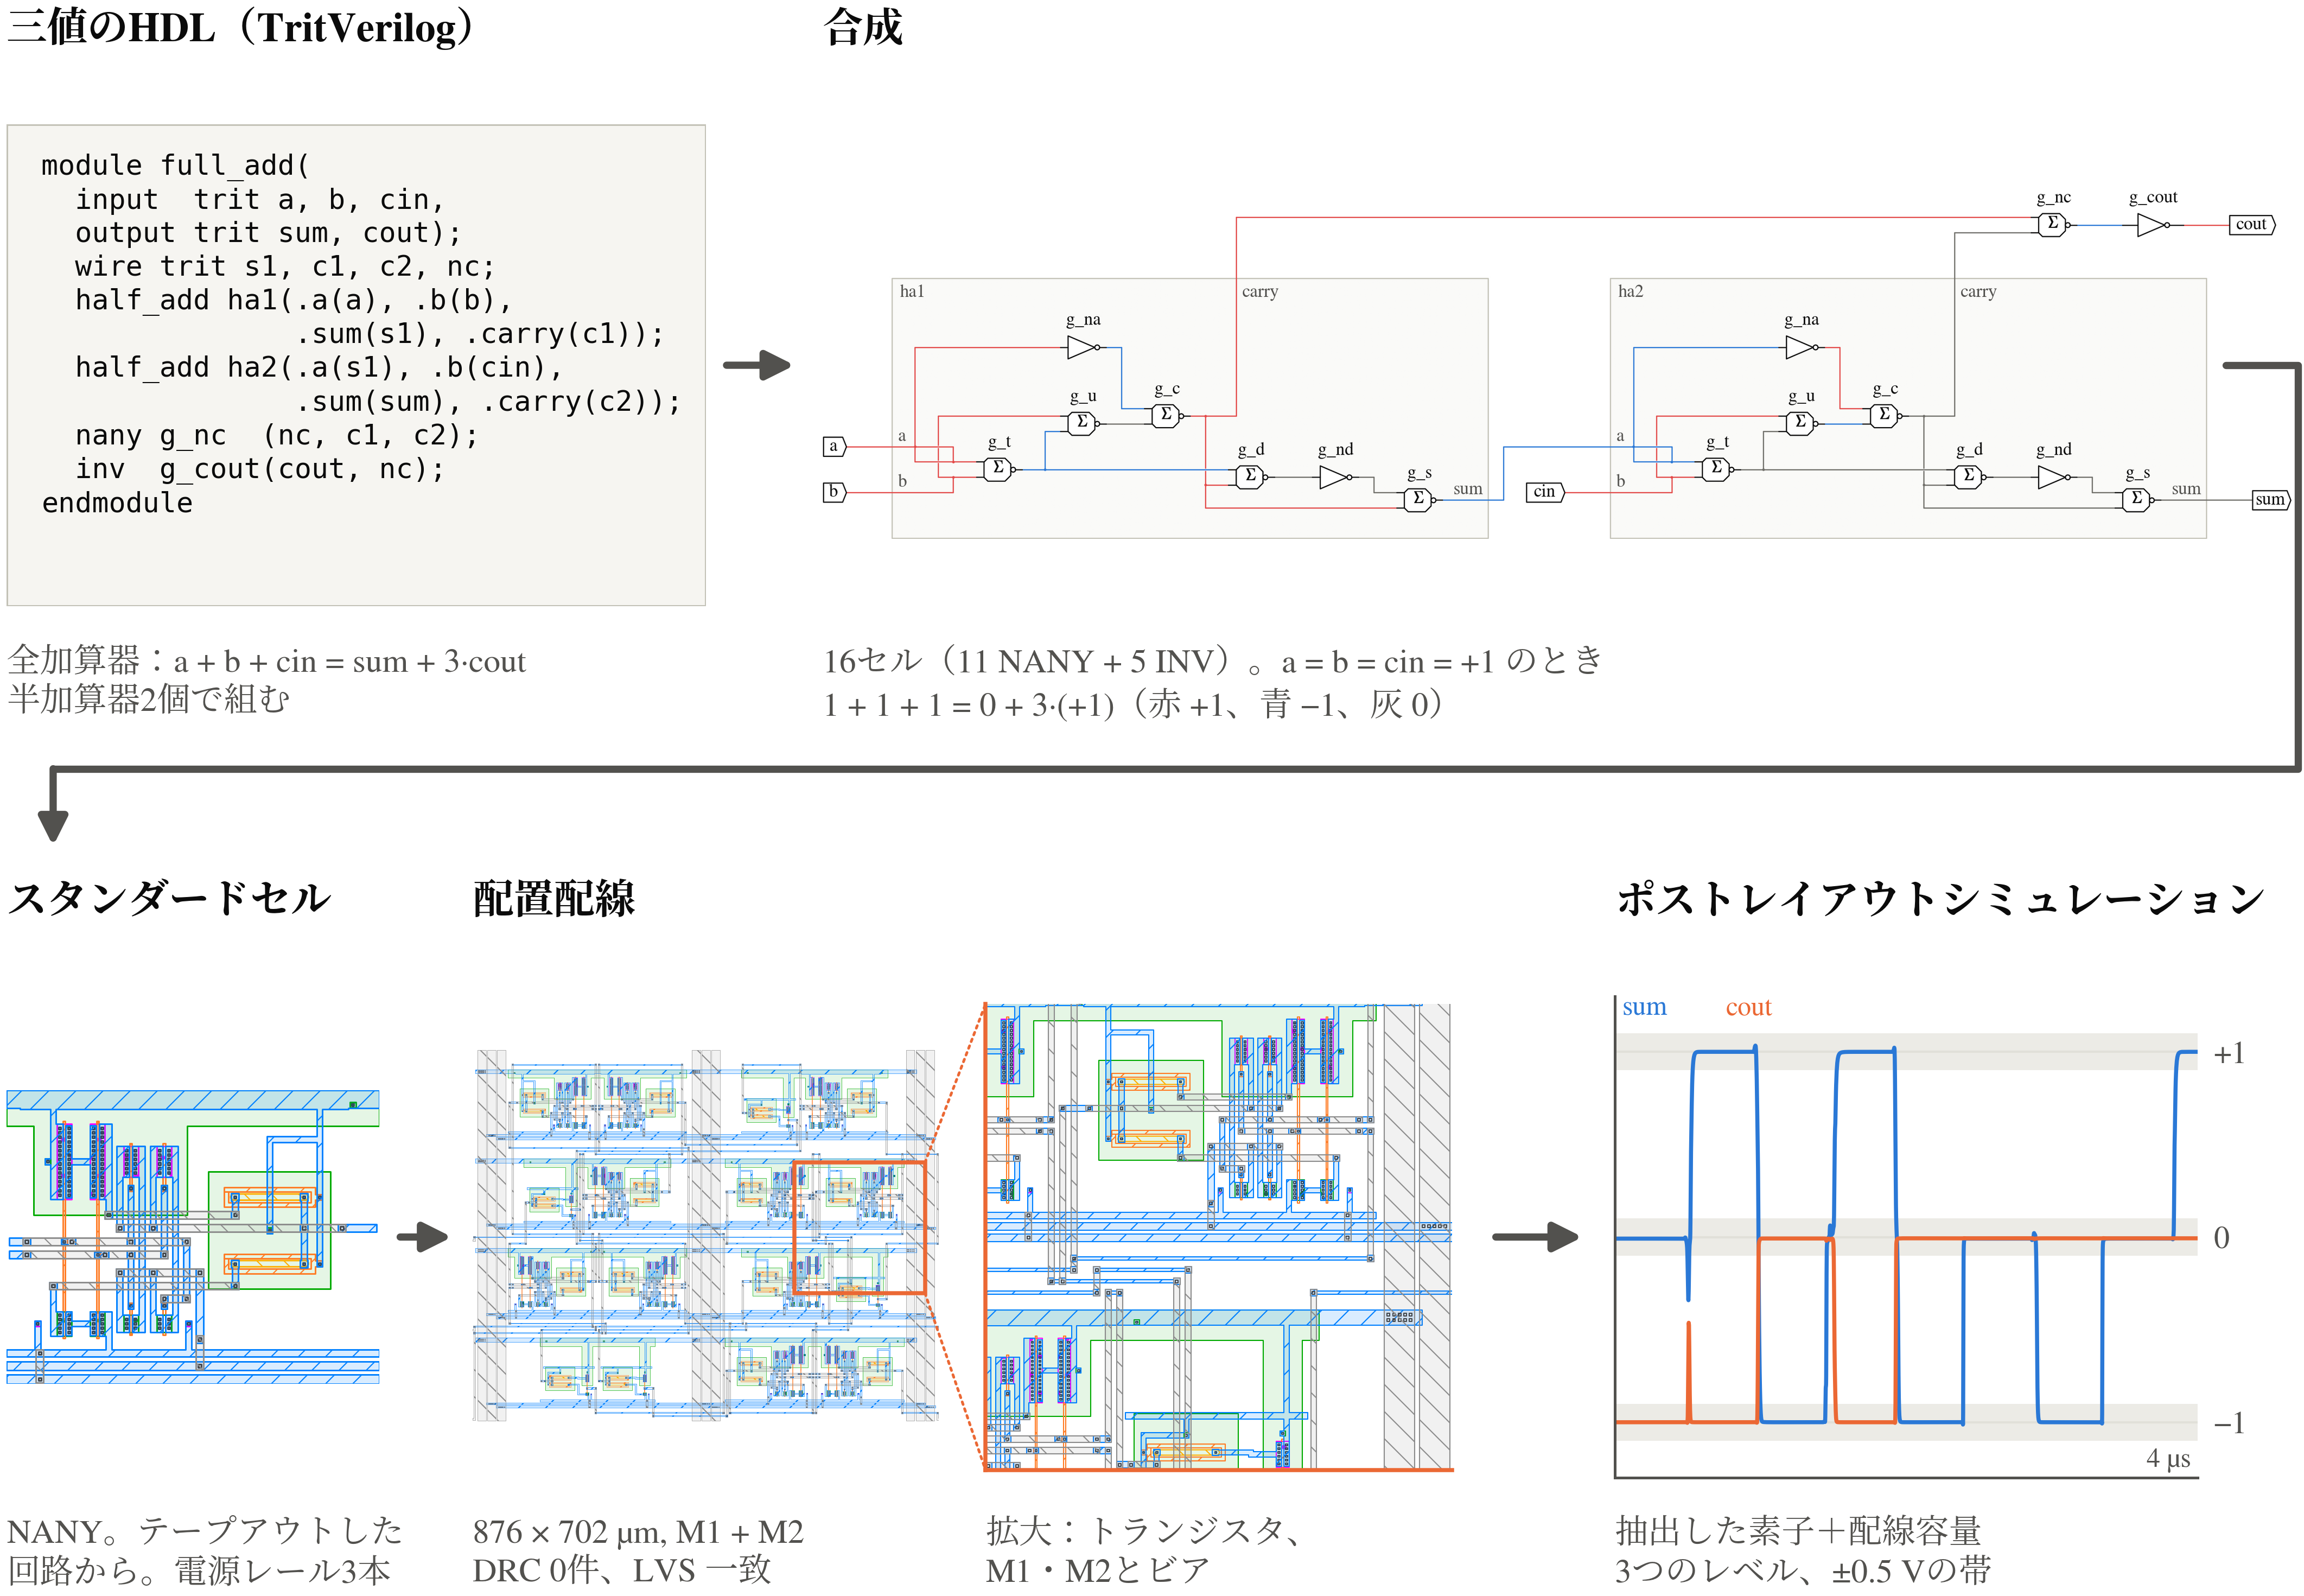

In [2]:
#@title 準備（最初に実行） { display-mode: "form" }

import os, sys, json, time, subprocess, importlib.util, re
from pathlib import Path
SOURCE_URL = "https://github.com/PenguinEino/tritflow.git"
SOURCE_REF = os.environ.get("TRITFLOW_REF", "8f77584a7d39be94b475fb4f2ddfc9be4a9ea190")
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False

def git(*args, progress=None):
    """Run git; with ``progress``, show git's own counter on one redrawn line."""
    if progress is None:
        return subprocess.check_output(["git", "-C", str(ROOT), *args], text=True).strip()
    from IPython.display import display, HTML
    style = "font:13px/1.6 ui-monospace,Menlo,Consolas,monospace;white-space:pre"
    line = display(HTML(f'<div style="{style}">⠿ {progress}</div>'), display_id=True)
    process, text, started = subprocess.Popen(["git", *args], stderr=subprocess.PIPE, text=True), "", time.monotonic()
    for chunk in iter(lambda: process.stderr.read(64), ""):
        text += chunk
        parts = [p.strip() for p in re.split(r"[\r\n]", text)[:-1] if p.strip()]
        if parts:
            line.update(HTML(f'<div style="{style}">⠿ <b>{progress}</b>  <span style="color:#8a8f98">{parts[-1][:80]}</span></div>'))
    if process.wait():
        raise RuntimeError(f"git {' '.join(args[:2])} failed:\n{text[-2000:]}")
    line.update(HTML(f'<div style="{style}"><span style="color:#1a9c4a">✓</span> <b>{progress}</b>  '
                     f'<span style="color:#8a8f98">{time.monotonic()-started:.1f}s</span></div>'))

if IN_COLAB:
    ROOT = Path("/content/tritflow")
    if not re.fullmatch(r"[0-9a-f]{40}", SOURCE_REF):
        raise ValueError("TRITFLOW_REF must be a full 40-character commit")
    if not ROOT.exists():
        git("clone", "--progress", "--no-checkout", "--depth", "1", "--filter=blob:none",
            SOURCE_URL, str(ROOT), progress="GitHubからソースを取得")
        git("-C", str(ROOT), "fetch", "--progress", "--depth", "1", "origin", SOURCE_REF,
            progress=f"コミット {SOURCE_REF[:7]} を取得")
        git("-C", str(ROOT), "switch", "--detach", SOURCE_REF, progress="ファイルを展開")
    if git("rev-parse", "HEAD") != SOURCE_REF or git("status", "--porcelain", "--untracked-files=no"):
        # A runtime left by another version of this notebook: move it to the pinned commit and
        # drop the modules the kernel already imported from the old checkout.
        git("-C", str(ROOT), "fetch", "--progress", "--depth", "1", "origin", SOURCE_REF,
            progress=f"コミット {SOURCE_REF[:7]} に切り替え")
        git("reset", "--hard", SOURCE_REF)
        for name, module in list(sys.modules.items()):
            if str(getattr(module, "__file__", "") or "").startswith(str(ROOT)):
                del sys.modules[name]
else:
    candidates = [Path(os.environ.get("TRITFLOW_ROOT", ".")), Path.cwd(), Path.cwd().parent]
    ROOT = next((p.resolve() for p in candidates if (p/"tritflow").is_dir() and (p/"notebook").is_dir()), None)
    if ROOT is None:
        raise RuntimeError("run from the TritFlow checkout or set TRITFLOW_ROOT")
sys.path[:0] = [str(ROOT), str(ROOT/"notebook")]
from live import step, run_stages, set_language as set_notebook_language
set_notebook_language("ja")
from runtime_support import SETUP_SCHEMA, setup_identity, check_runtime, print_tool_versions
runtime = ROOT/"notebook/runtime.json"
if IN_COLAB and (not runtime.is_file()
                 or json.loads(runtime.read_text()).get("TRITFLOW_SETUP_SHA256") != setup_identity(ROOT)):
    os.environ["TRITFLOW_NOTEBOOK_LANGUAGE"] = "ja"
    run_stages(["bash", str(ROOT/"notebook/colab_setup.sh"), "--source", str(ROOT)])
if runtime.is_file():
    os.environ.update(json.loads(runtime.read_text()))
    sys.path.insert(0, os.environ["TRITFLOW_PYTHON_TARGET"])
os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")
with step("ツールを確認") as s:
    check_runtime()
    tools = print_tool_versions()
    s.done(" · ".join(re.search(r"(KLayout [\d.]+|ngspice-\d+)", v)[1] for v in tools.values()))
BUILD = Path(os.environ.get("TRITFLOW_NOTEBOOK_BUILD", "/content/build" if IN_COLAB else ROOT/"build/notebook")).resolve()

from live import need, provides, install_error_view, LayoutView
from views import pick_input, stimulus, bus_picker, cell_counts, schematic_view, scope_figure, timing_table, wire_table, delay_table, transient_conditions, dc_conditions, note
from IPython.display import HTML, display
import plotly.io as pio
pio.renderers.default = "colab"
from inverter_views import inverter
from pnr_views import replay
from cell_views import closure_view, cell_tables, cell_row
from tritflow import CELLS_DIR
from tritflow.sim.sizing import sweep_dimensions, load_grid
from tritflow import flow
from tritflow.viz.layout import gds_viewer
from tritflow.schematic import set_language
set_language("ja")
install_error_view()
for name, cell in {"source": "1-1 HDL", "net": "1-2 合成する", "lay": "1-3 配置配線する",
                   "lvs": "1-4 DRCとLVS", "post": "1-5 ポストレイアウトシミュレーション",
                   "dot4": "3-8 論理合成する", "dot4_layout": "4-1 配置配線する",
                   "dot4_lvs": "5-1 DRCとLVS", "dot4_extracted": "5-2 抽出と配線容量", "dot4_post": "5-3 ポストレイアウトシミュレーション",
                   "dot_scaling": "6-1 積和の規模と面積",
                   "reuse_source": "6-4 HDLを変更する"}.items():
    provides(name, cell)


Python: numpy 2.4.3, scipy 1.17.1, matplotlib 3.10.8, plotly 7.1.0
KLayout: KLayout 0.30.9 (/home/ishi-kai/bin/klayout/klayout)
ngspice: ngspice-42 : Circuit level simulation program (/home/ishi-kai/.local/opt/tritflow-ubuntu-24.04/bin/ngspice)


## 1. 最初の回路：`a & ~a` をGDSにする

本章では、小さな三値回路の1つである `a & ~a` を、HDLからGDSとポストレイアウトシミュレーションまで一通り通し、TritFlowのフロー全体を見る。各段の中身は2章以降で順に詳しく見る。

二値の論理では、`a & ~a` はaが何であっても偽になる。三値ではそうならない。

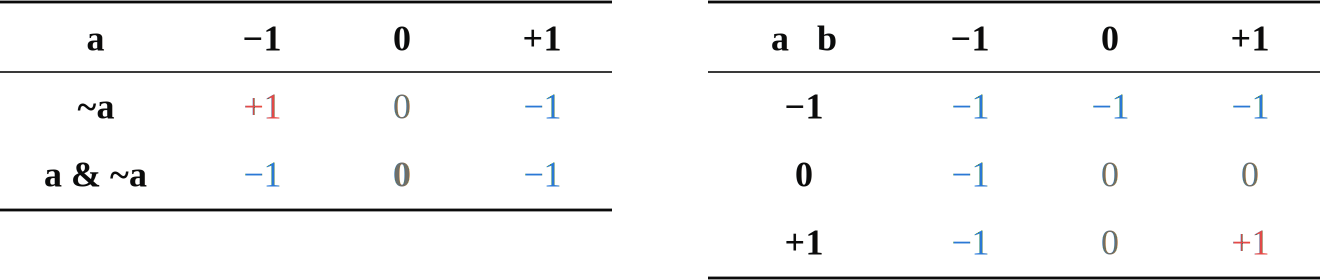

TritFlowのHDL（TritVerilog）で書くと、次のようになる。

In [3]:
# 1-1 HDL
source = """
module first(input trit a, output trit y);
  assign y = a & ~a;
endmodule
"""

論理合成する。三値の式を三値のセルに直接写像し、全入力の網羅で元のHDLとの等価性を検証する。

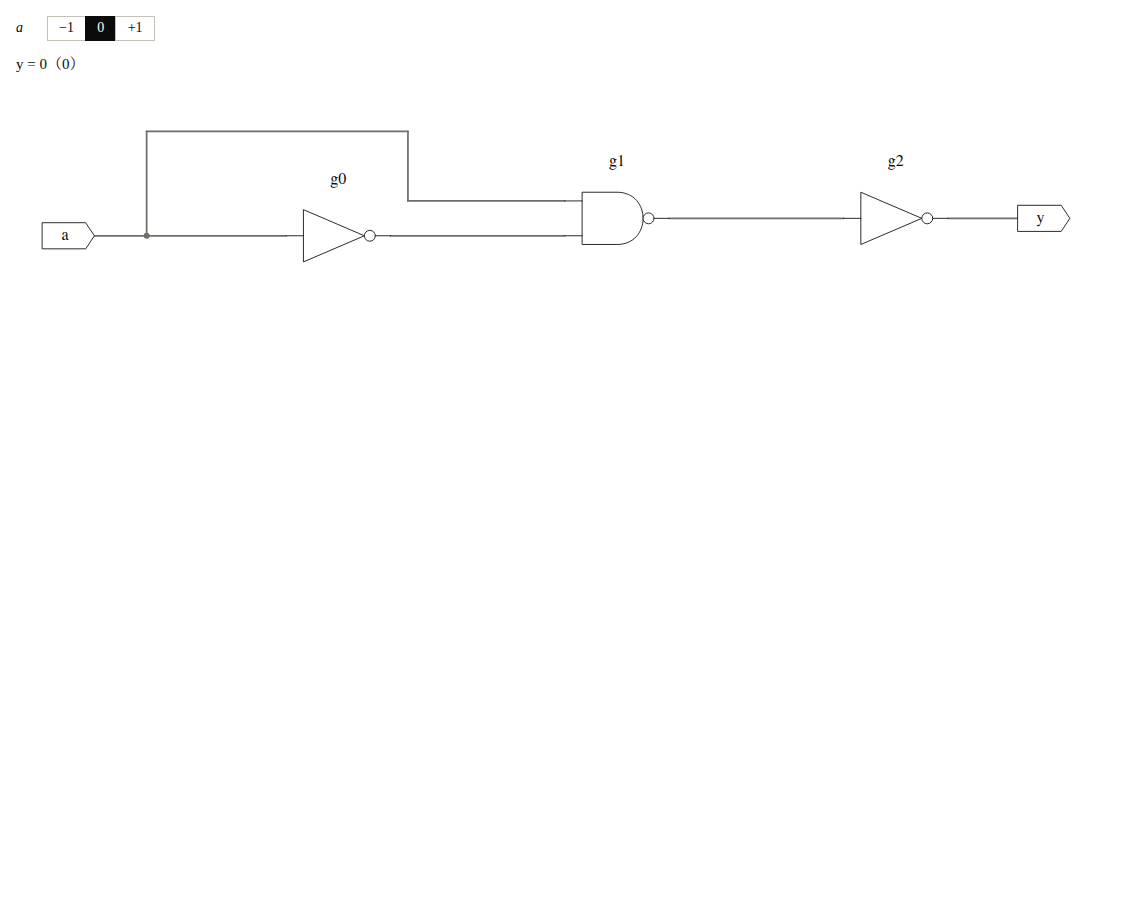

In [4]:
# 1-2 合成する
need("source", why="合成するHDLは、1-1に書いてあります。")
with step("HDLを読み込んで合成") as s:
    net = flow.loads(source).synthesize()
    s.done(" · ".join(f"{cell}×{n}" for cell, n in net.report()["cells"].items())
           + (" · 全入力で等価" if net.equivalence["passed"] else " · 等価でない"))
bus_picker(net)

配置配線する。三値セル用に作った配置配線器で、各セルを貫く3本の電源レール（VDD・VMID・VSS）を保ったまま、TR-1umのM1/M2の2層で配線する。

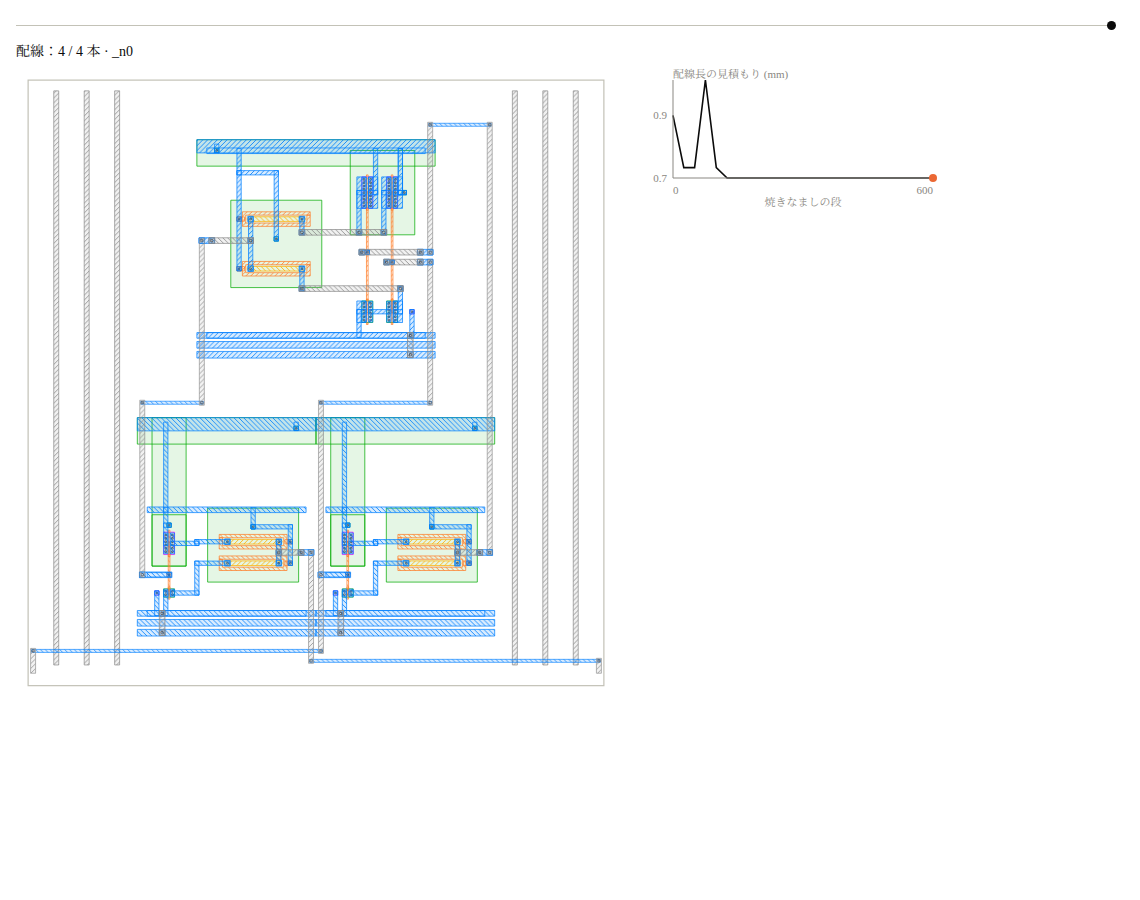

In [5]:
# 1-3 配置配線する
need("net", why="配置配線する回路 net は、1-2で合成します。")
with step("配置配線", view=LayoutView()) as s:
    lay = net.place_and_route(output_dir=BUILD/net.top, seed=0)
    width, height = lay.stats["die_size_um"]
    s.done(f"{lay.stats['instance_count']}セル · {width:.0f} × {height:.0f} µm · 配線 {lay.stats['routed_nets']}本",
           picture=replay(lay))

PDKの公式デッキでDRCとLVSを行う。

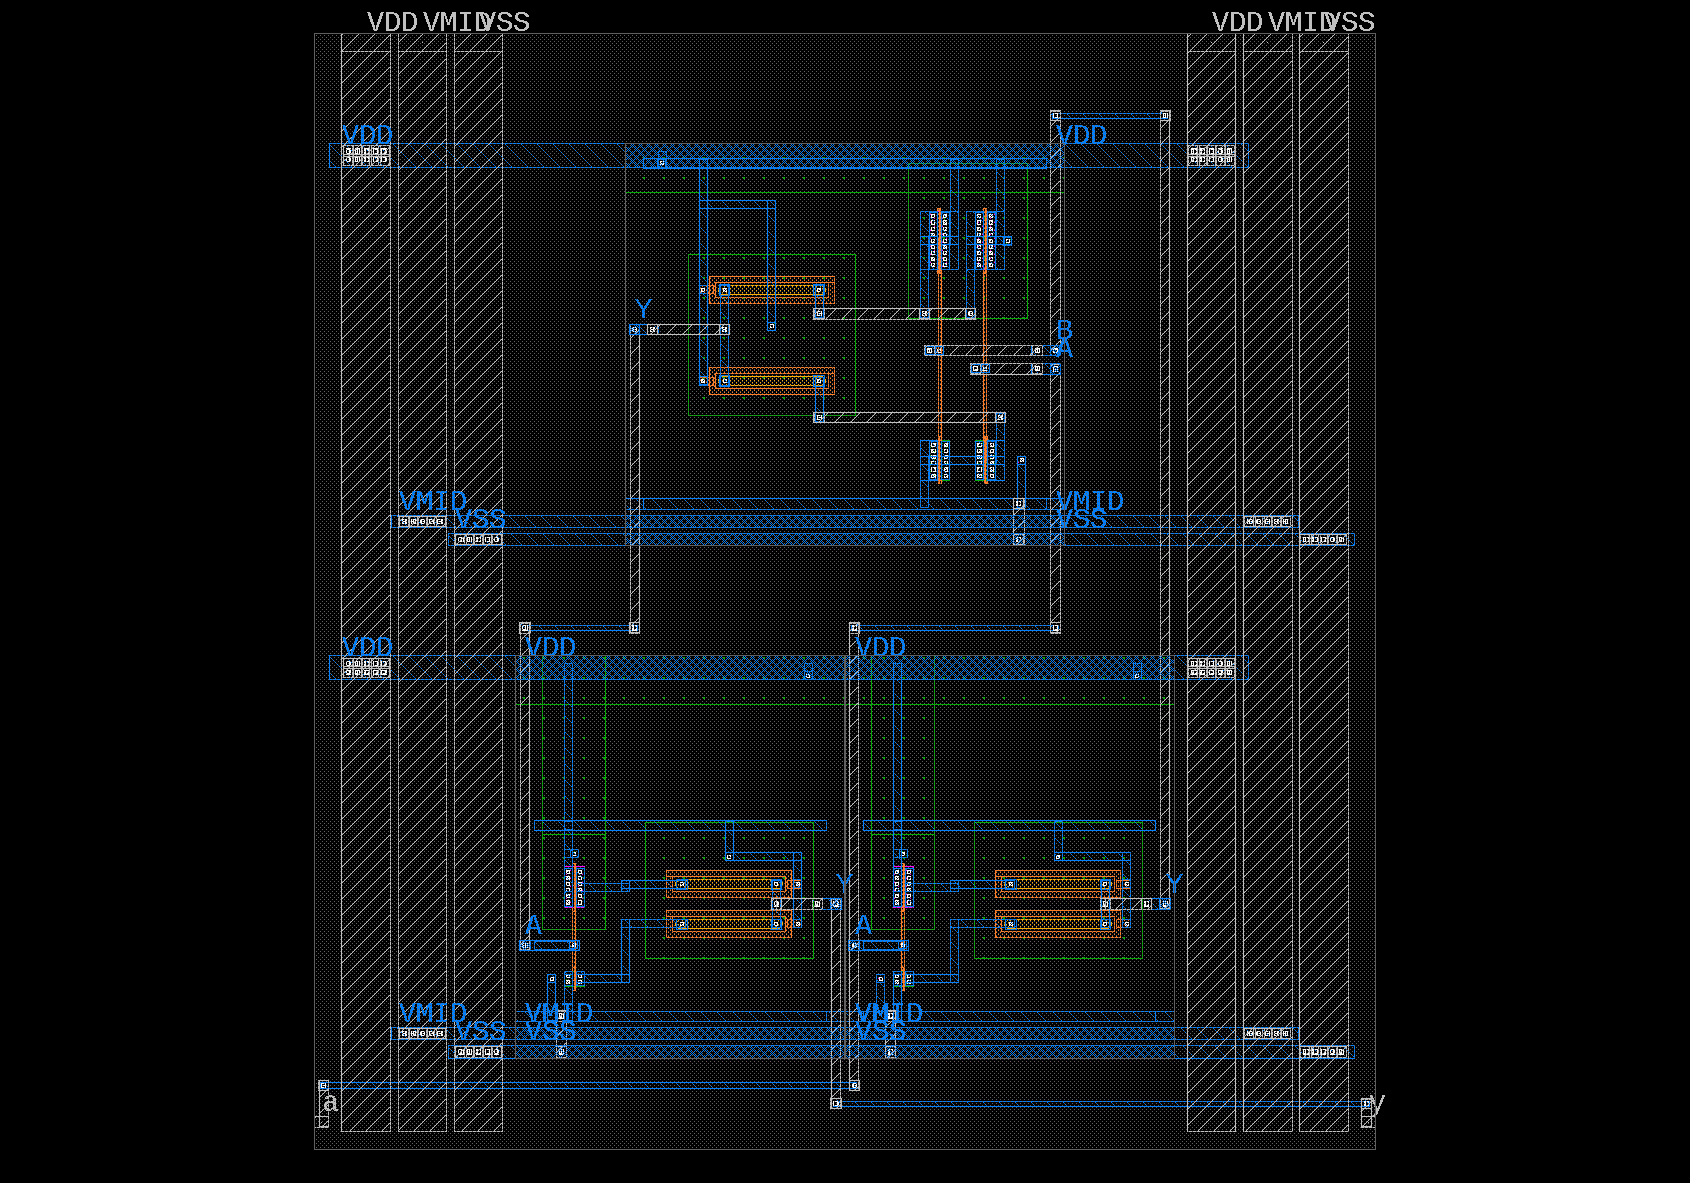

In [6]:
# 1-4 DRCとLVS
need("lay", why="DRCとLVSは、1-3で作ったGDSを調べます。")
with step("DRC") as s:
    drc = lay.drc()
    s.done(f"違反 {drc['violations']}件")
with step("LVS") as s:
    lvs = lay.lvs()
    s.done("一致" if lvs["matched"] else "不一致")
gds_viewer(lay.gds_path)

ポストレイアウトシミュレーションを行う。GDSから見積もった配線容量を加え、各区間で出力が理想電圧（−5/0/+5 V）の±0.5 V以内に入るかを三値のテストベンチで判定する。入力ごとの各ネットの値と波形を示す。

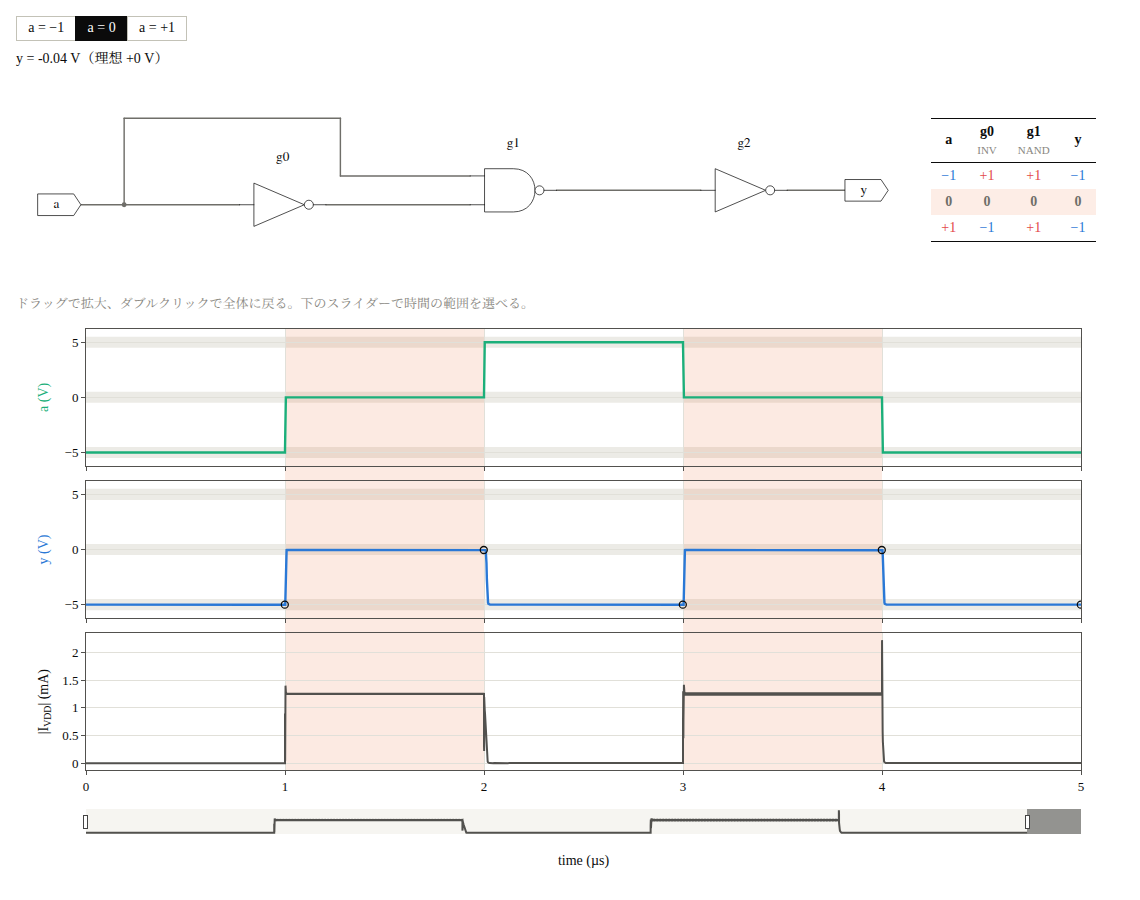

In [7]:
# 1-5 ポストレイアウトシミュレーション
need("lvs", why="シミュレーションは、1-4でLVSが一致したGDSから回路を取り出して動かします。")
with step("抽出と配線容量") as s:
    extracted = lay.extract()
    signals = [n for n in extracted.capacitance["nets"] if n not in ("VDD", "VMID", "VSS")]
    s.done(f"信号{len(signals)}本に配線容量を追加")
with step("ngspice") as s:
    post = extracted.simulate(stimulus(net), load=100e-15, hold_s=1e-6, step_s=2e-9,
                              edge_s=1e-9, temperature_c=27)
    s.done("全区間で ±0.5 V の帯に入った" if post["measurements"]["passed"] else "帯に入らない区間がある")
pick_input(net, post)
transient_conditions(post, load_f=100e-15)

ここまでのフローを振り返ると、次のようになる。

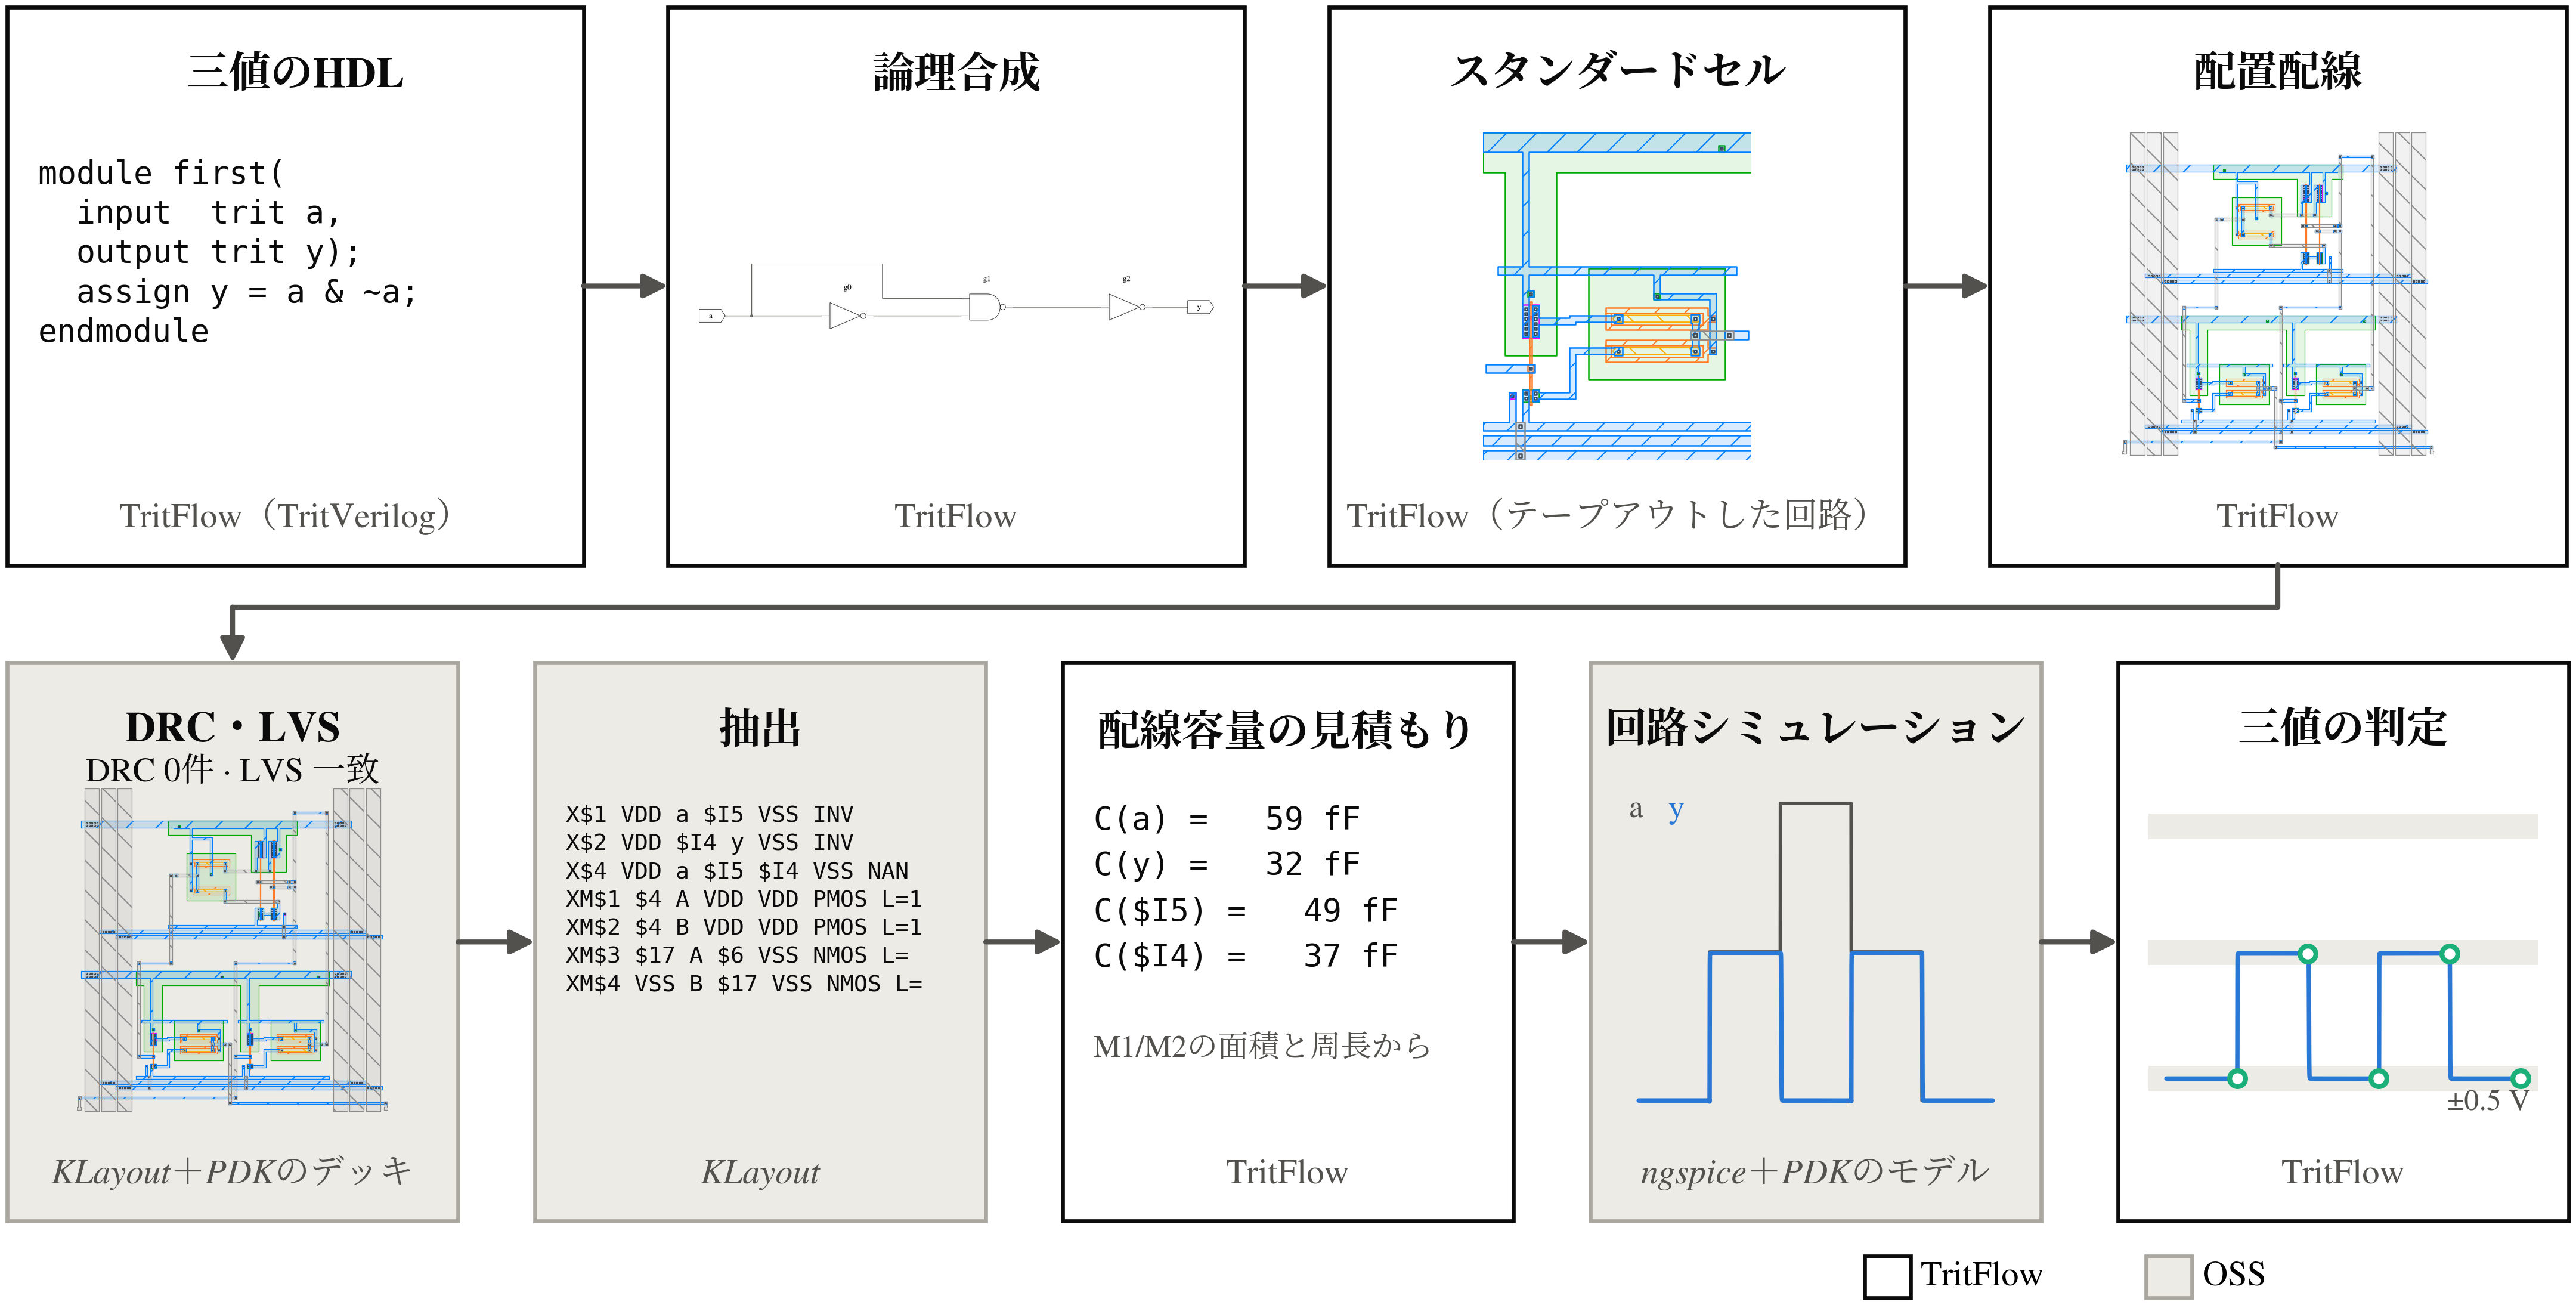

ここまでで、フロー全体を一通り体験した。次章からは各部分の設計を詳しく見ていく。まず2章では、フローの土台であるセルのうち、最も基本的なINVの中を見る。

## 2. セル

1章の回路はINVとNANDの2種類のスタンダードセルでできていた。本章ではTritFlowで用いるスタンダードセルを説明する。まず最も基本的なINVを例に、CMOSで3つの電圧レベルをどう作るかを確かめる。次に、三値の任意の論理がどのようなセルから作れるのかを示し、最後に、テープアウトした回路をどのように配置配線できるスタンダードセルにしたのかを見る。

### 2.1 INV：3つのレベルを作る

二値のINVとの違いは0 Vを出すために上下のMOSを同時にオンにし、分圧で中間のレベルを作る点にある。

TritFlowのINVはVDDとVSSの間にPMOS、拡散抵抗（PDKのデバイス名RR）2本、NMOSを直列につないだ回路で、出力Yは2本の抵抗の間からとる。

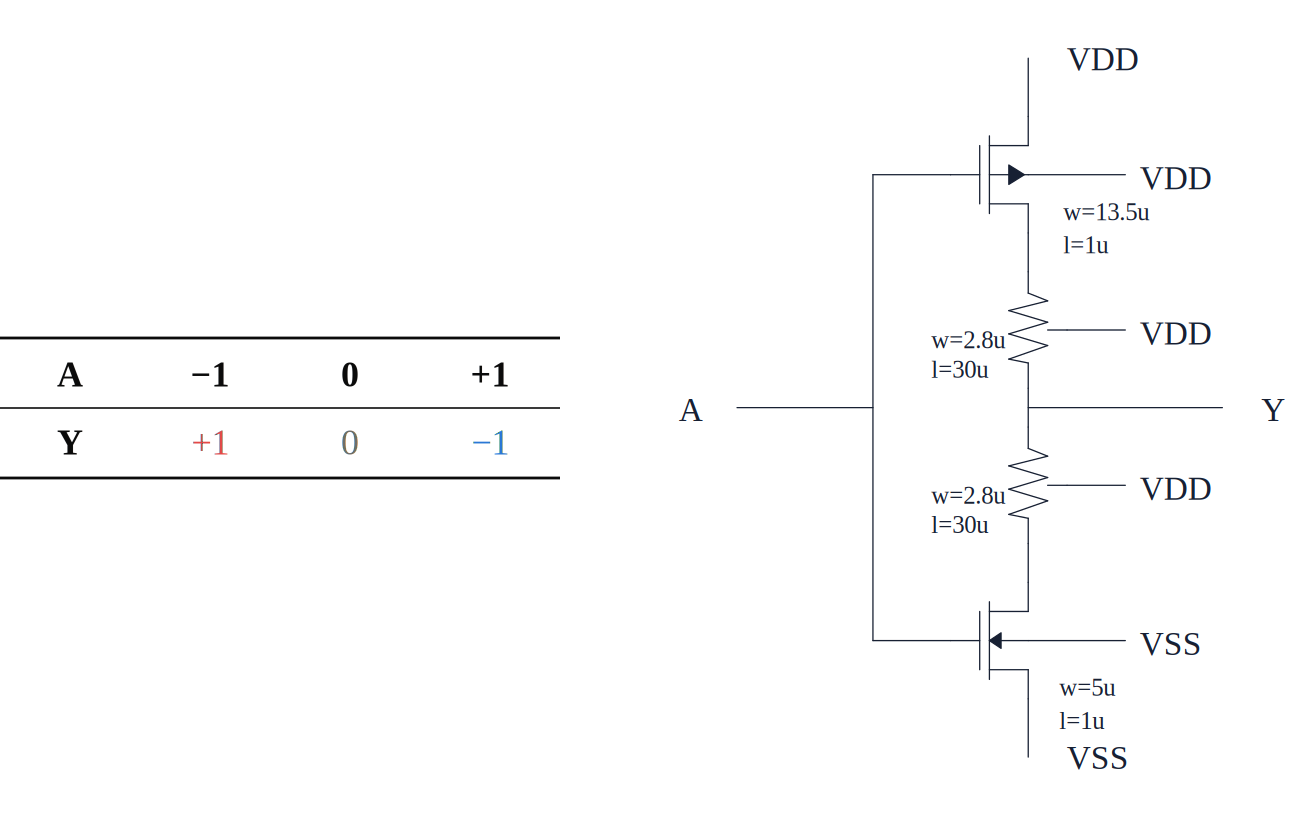

入力が±5 Vのときは片方のMOSだけがオンになり、Yはそちら側のレールにプルアップまたはプルダウンされる。入力が0 Vでは両方のMOSがオンになる。オンのMOSをオン抵抗 $r_{on} \propto (W/L)^{-1}$ で近似し、上側を $R_u = r_{on,P} + R_{RP}$、下側を $R_d = r_{on,N} + R_{RN}$ とすると、

$$V_Y = V_{SS} + (V_{DD}-V_{SS})\frac{R_d}{R_u+R_d},\qquad I = \frac{V_{DD}-V_{SS}}{R_u+R_d}$$

となる。0 Vはどのレールからも供給されず、$R_u = R_d$ の釣り合いだけで作られ、その間は静的電流 $I$ が流れ続ける。以下の寸法ではRRの抵抗値が近似したオン抵抗の20倍以上あり、0のレベルはMOSのばらつきよりも、同じ形状の2本の抵抗の比によって支配的に決まる。


#### SPICEでのシミュレーション

テープアウトした寸法を含む90通りの寸法について、ngspiceとPDKのモデルでDC解析した結果を示す。

寸法は中間レベルの精度、遅延、面積、静的電流のトレードオフで決めた。MOSのゲート長は駆動能力と面積から最小の1 µm、RRの幅は最小の2.8 µmとした。入力0 Vでの出力は $R_u = R_d$、すなわち $r_{on,P} + R_{RP} = r_{on,N} + R_{RN}$ のとき0 Vになる。正孔の移動度は電子より低いため、PMOSの幅をNMOSより広くとって両者のオン抵抗をそろえ、出力オフセットを打ち消した。中間レベルの雑音余裕として、入力 −1〜+1 Vで出力が ±0.5 V以内に収まることを目標とした。RRの長さはテープアウトしたチップ全体の静的電流を電源配線とビアの許容電流に収めるように30 µmとした。MOSの寸法はRRを延ばす前のまま変えていないため、入力0 Vで数十mVのオフセットが残るが、±0.5 Vの判定帯に対しては十分小さい。

採用寸法ではPMOSの幅が13.5 µm、NMOSの幅が5 µmである。PDKのゼロバイアスの抵抗式から各RRを10.835 kΩ、移動度・酸化膜厚・しきい値からMOSを線形抵抗で近似すると、$r_{on,P}=0.492$ kΩ、$r_{on,N}=0.399$ kΩとなる。RRとの比はそれぞれ22.0倍、27.2倍である。これを分圧の式に代入すると、

$$V_Y=-5+10\frac{11.234}{11.327+11.234}\simeq -0.021\ \mathrm{V},\qquad I=\frac{10}{11.327+11.234}\simeq 0.443\ \mathrm{mA}$$

となる。SPICEの −0.040 V、0.407 mAとの差は、近似がRRの電圧・基板バイアス依存とMOSの非線形性を省いていることによる。これらの近似値はSPICEの電流に合わせて調整したものではない。

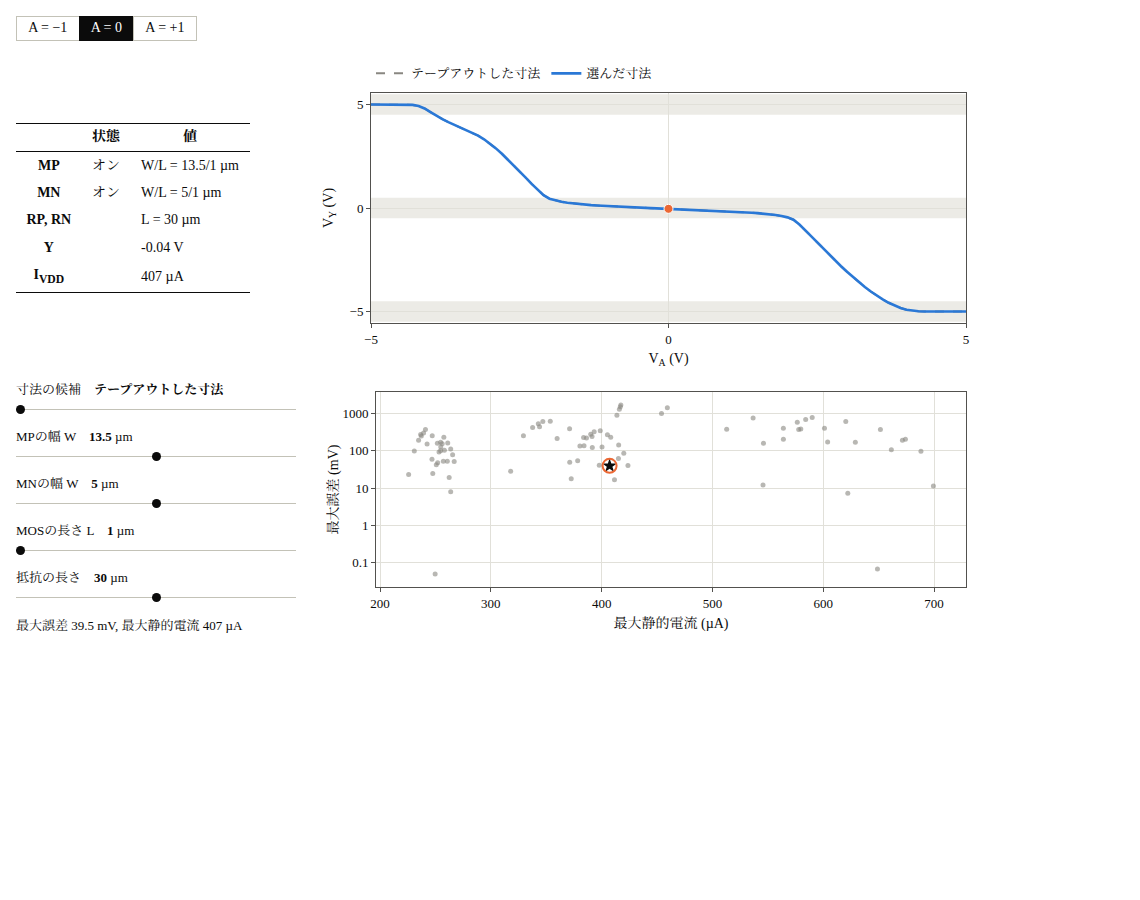

In [8]:
# 2-1 INVのDC解析と寸法
with step("ngspice（INVのDC解析）") as s:
    spice = sweep_dimensions("INV", [], workdir=BUILD/"inv")
    zero = next(r for r in spice["rows"][0]["dc"] if r["input_trits"] == [0])
    s.done(f"入力 0 V：Y = {zero['output_v']['Y']:+.3f} V · {abs(zero['rail_current_a']['VDD'])*1e3:.3f} mA")
with step("寸法の記録を照合") as s:
    grid = load_grid("INV")
    s.done(f"{len(grid['rows'])}通り · 回路・モデル・解析コードが一致")
from predictions import divider, rail_power
from tritflow import PDK_ROOT
from style import figure_css, table_css
inv_hand = divider(grid["rows"][grid["adopted_index"]]["dimensions"], PDK_ROOT)
upper, lower = inv_hand["upper"], inv_hand["lower"]
resistances = [upper["rr_ohm"], upper["ron_ohm"], lower["ron_ohm"],
               upper["total_ohm"], lower["total_ohm"]]
comparison = [("V<sub>Y</sub> (V)", inv_hand["output_v"], zero["output_v"]["Y"], "+.3f"),
              ("I (mA)", inv_hand["current_a"]*1e3, abs(zero["rail_current_a"]["VDD"])*1e3, ".3f"),
              ("P (mW)", inv_hand["power_w"]*1e3,
               rail_power(zero, grid["conditions"]["supplies_v"])*1e3, ".3f")]
display(HTML('<style>'+figure_css('.inv-estimate')+table_css('.inv-estimate')+'</style>'
    + '<div class="inv-estimate"><table><tr>'
    + ''.join(f'<th>{label}<small>kΩ</small></th>' for label in
              ('R<sub>RR</sub>', 'r<sub>on,P</sub>', 'r<sub>on,N</sub>', 'R<sub>u</sub>', 'R<sub>d</sub>'))
    + '<th>R<sub>RR</sub>/r<sub>on,P</sub></th><th>R<sub>RR</sub>/r<sub>on,N</sub></th></tr><tr>'
    + ''.join(f'<td>{r/1e3:.3f}</td>' for r in resistances)
    + f'<td>{upper["rr_ohm"]/upper["ron_ohm"]:.1f}</td><td>{lower["rr_ohm"]/lower["ron_ohm"]:.1f}</td></tr></table>'
    + '<table style="margin-top:1em"><tr><th>入力0 V</th><th>抵抗による近似</th><th>SPICE</th></tr>'
    + ''.join(f'<tr><td>{label}</td><td>{estimate:{fmt}}</td><td>{measured:{fmt}}</td></tr>'
              for label, estimate, measured, fmt in comparison)
    + '</table></div>'))
inverter(spice, grid)
dc_conditions()

### 2.2 完全性：三値の論理は何から作れるか

論理合成はHDLで書いた論理を用意したセルの組合せに置き換える作業である。どんな論理でも置き換えられるには、セルの組が**機能的に完全**である必要がある。機能的に完全とはその組のセルをつなげば、あらゆる論理関数を作れることをいう。二値では、NANDが1種類あれば完全である。

三値ではNANYと、+1を出す定数セル（TIEP）の2種類だけで機能的に完全になる。定数は−1を出すTIENでもよい。NANYは2つの入力の和を−1から+1の範囲に切り詰め（sat）、符号を反転するセルで、$\mathrm{NANY}(a, b) = -\mathrm{sat}(a+b)$ である。

根拠はSłupecki（1939年）の判定法である。三値の関数の組は次の2つを満たせば完全になる。

1. 入力が1本の関数（1入力関数）を、すべて作れる。入力aは−1・0・+1の3通りで、それぞれに出力を3通りから選べるので、1入力関数は 3 × 3 × 3 = 27通りある。
2. 次の性質をもつ2入力関数 f(a, b) を、1つ作れる。a と b のどちらの入力も無視せず（その入力だけを変えると出力が変わる場合がある）、出力に−1・0・+1のすべてが現れる。

2はNANY自身が満たす。NANY(a, 0) = −a なので a だけを変えると出力が変わり、b についても同じである。出力も−1・0・+1のすべてをとる。1は入力aと+1の定数から始め、手元の関数をNANYの入力につないで新しい関数を作ることを、新しい関数が増えなくなるまで繰り返して確かめる。表には最初の数段で作れる関数を示す。段はaと定数から数えたNANYの深さである。

In [9]:
# 2-2 NANYと +1 の定数から作れる1入力関数
from completeness import generations, surjective_and_depends_on_both, nany
found = generations(binary=(nany,), constants=(1,))
print(f"作れた1入力関数：{len(found)} / 27、最も深いもので {max(found.values())} 段")
print("NANYは2つの入力の両方に依存し、出力に−1・0・+1のすべてが現れる：", surjective_and_depends_on_both(nany))
closure_view(found)

作れた1入力関数：27 / 27、最も深いもので 5 段
NANYは2つの入力の両方に依存し、出力に−1・0・+1のすべてが現れる： True


NANYだけでは完全にならない。$\mathrm{NANY}(0, 0) = 0$ なので、すべての入力が0のとき、NANYをどれだけつないでも出力は0のままで、a = 0 で0以外を出す関数も、+1や−1の定数も作れないからである。0以外の定数を1つ加えると、この制約が外れる。残りの定数は $\mathrm{NANY}(+1, +1) = -1$、$\mathrm{NANY}(+1, -1) = 0$ として作れるので、定数セルは1種類でよい。TritFlowの論理合成はこの性質を使って任意の真理値表をセルに置き換える（3章）。

### 2.3 スタンダードセルの一覧

TritFlowのスタンダードセルを以下に示す。INV・NAND・NOR・NANYはテープアウトした回路そのものである。INV・NAND・NORは完全性には要らないが、符号反転・min・maxを少ないセルで作るために持つ。BUFは1つの出力を多くの入力につなぐときの分割に、TIEP・TIEZ・TIENは定数に使う。各セルには以降の回路図で使う記号を添える。出力の丸は符号反転を表し、NANDとNORは二値と同じ形をとる。NANYは2つの入力の和をΣで表した記号で、和を−1から+1に切り詰めてから符号を反転する。TIEは出力する定数を記号の上に書く。

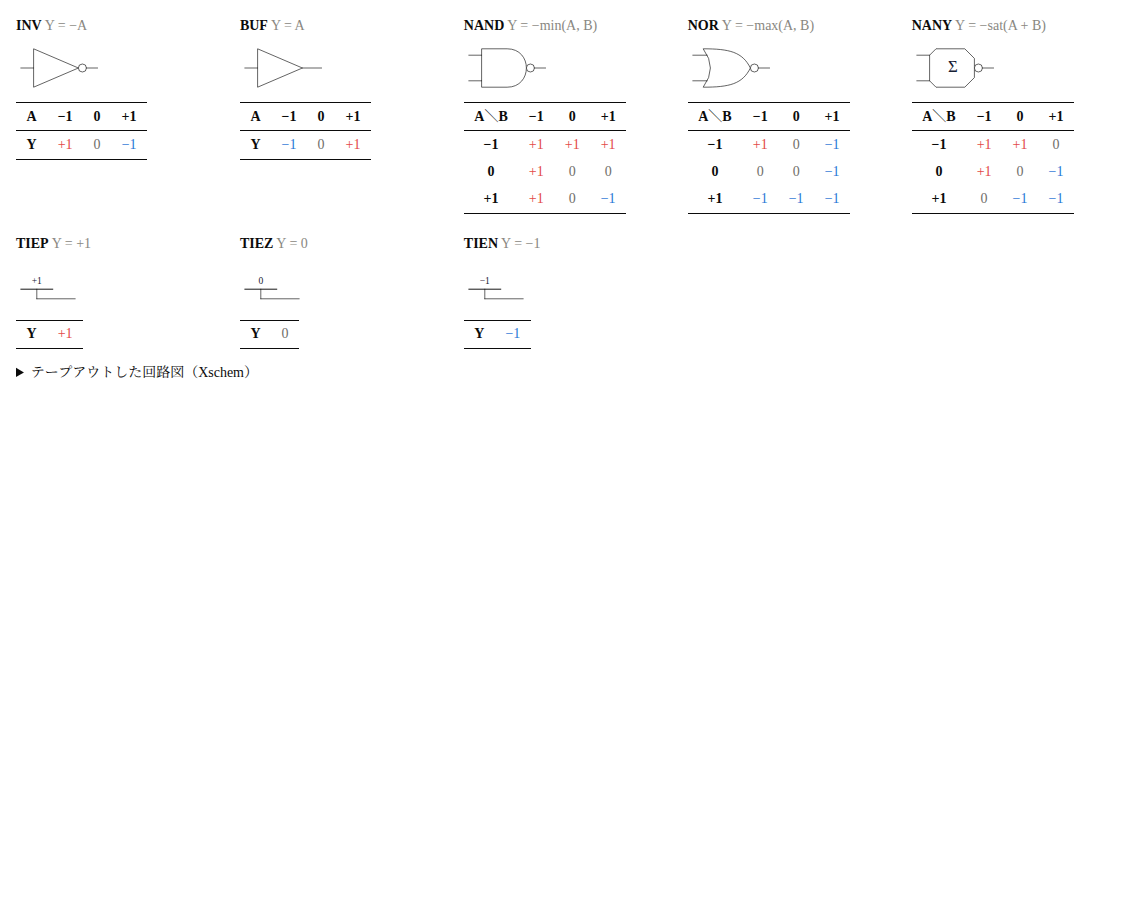

In [10]:
# 2-3 セルの真理値表
cell_tables(CELLS_DIR/"out", ROOT/"notebook/assets/schematics")

### 2.4 スタンダードセルのレイアウト

配置配線では、セルを横一列に並べ、隣どうしを突き当てて電源をつなぐ。そのため、すべてのセルが同じ高さと、同じ位置の電源レールを持つ必要がある。INV・NAND・NOR・NANYは、テープアウトした回路と素子寸法を保ったまま、この共通の枠に入れ直している。VDD・VMID・VSSの3本のレールがセルを横切り、信号ピンはM1の決まった高さに置いて、上を通るM2からビアで届くようにしている。左右反転して置いてもよい。

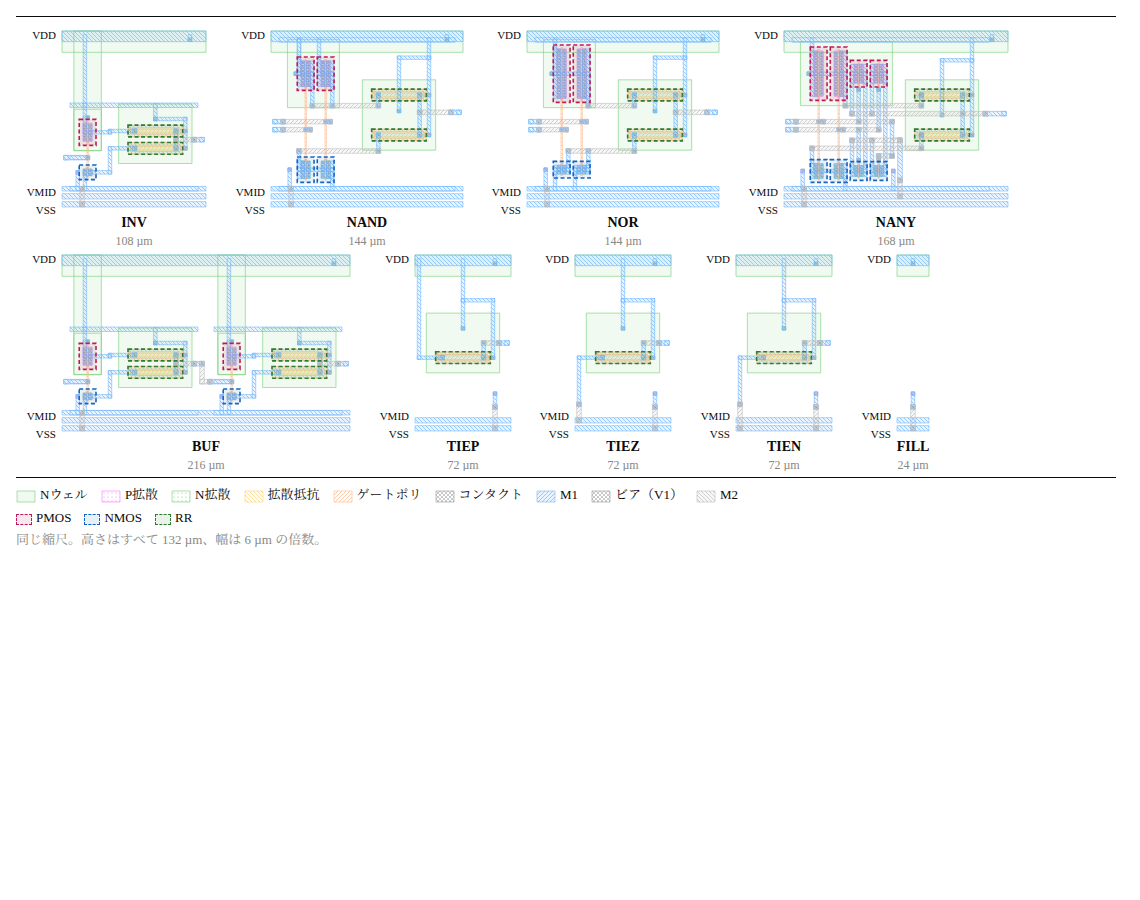

In [11]:
# 2-4 スタンダードセル
import json
cell_row(json.loads((CELLS_DIR/"out/library.json").read_text()), CELLS_DIR/"out")

## 3. HDLと論理合成

2章では、TritFlowのセルの組で任意の三値論理を作れることを確かめた。本章では、回路を書くHDLであるTritVerilogと、それをセルの回路網に置き換える論理合成を見る。TritVerilogはVerilogの組合せ回路の書き方を三値に広げたものである。書き方を順に紹介し、それぞれが何に合成されるかを示す。

### 3.1 値と数

信号の値（トリット）は−1・0・+1で、電圧の−5 V・0 V・+5 Vに対応する。条件として使うときは、偽・不定・真を表す。不定は物理的な0 Vに対応する有効なトリット0であり、Verilogの未定義値Xや高インピーダンスZとは異なる。`trit [1:0] a` のようなベクトルは平衡三値の整数を表し、桁 $i$ の重みは $3^i$ である。リテラルでは−1をTと書き、たとえば `2'tT1` は −1·3 + 1 = −2 を表す。2トリットで−4から+4を表せ、符号ビットは要らない。符号反転はすべての桁を反転するだけで済む。

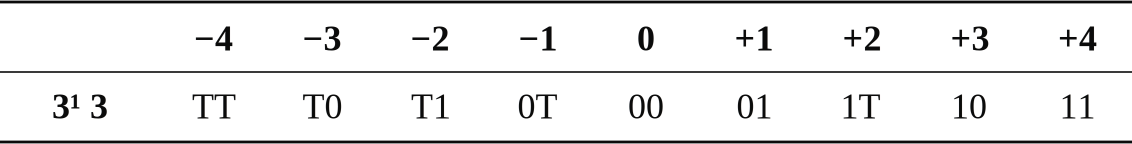

### 3.2 書き方

TritVerilogで書ける組合せ回路の書き方と、論理合成が置き換える回路を示す。

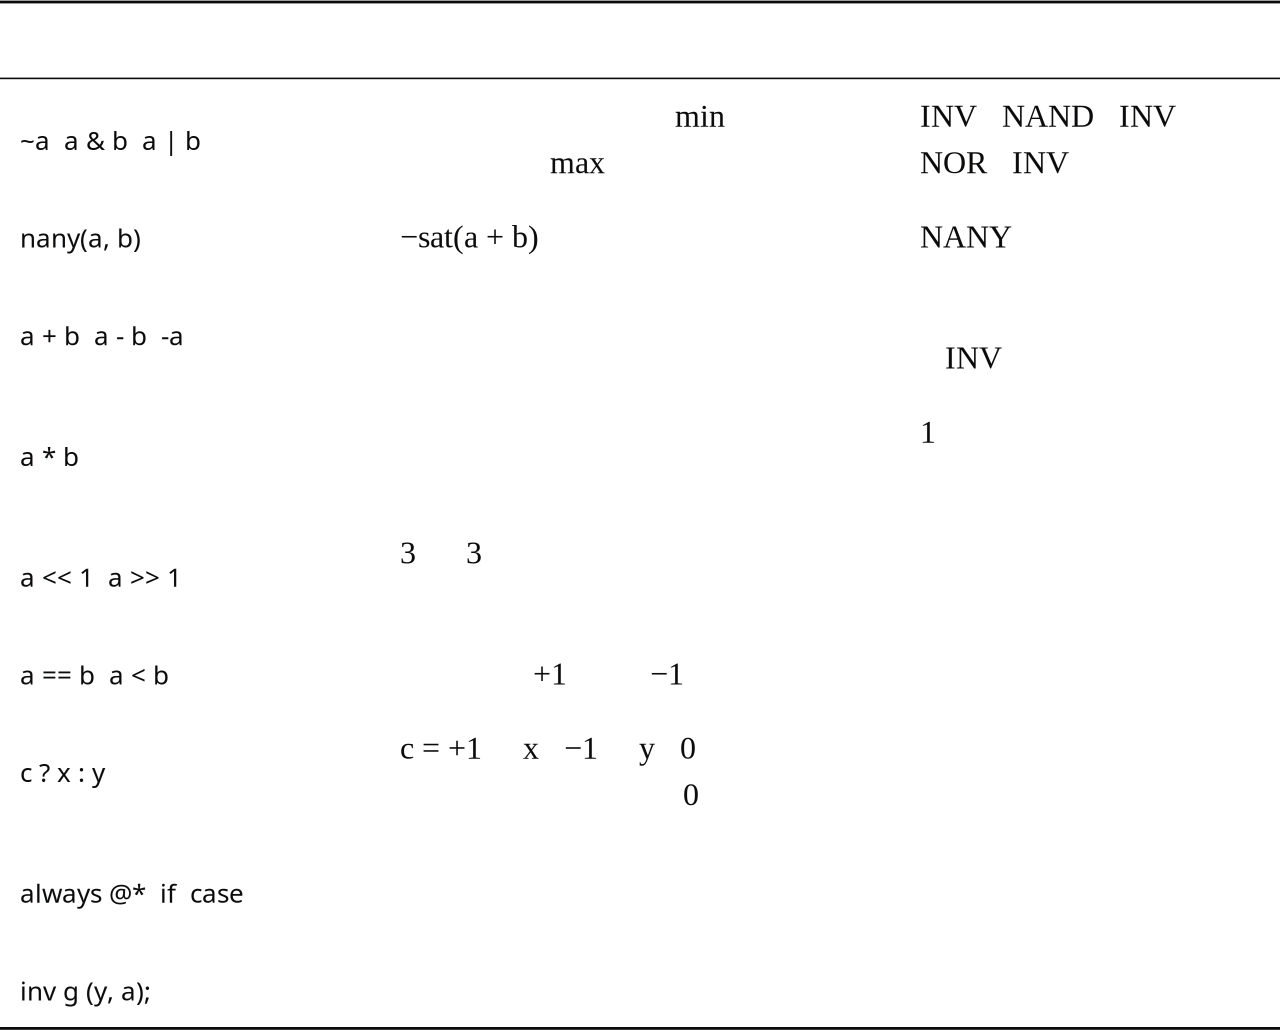

演算の桁数はVerilogと同じく代入先の桁数で決まり、短いオペランドは上の桁を0で埋める。代入先に収まらない上の桁は捨てられる。

### 3.3 論理合成の流れ

論理合成は次の段で進む。

1. 展開：HDLを構文解析し、モジュールの階層、パラメータ、`generate` を展開して、式の中間表現にする。`always @*` の中の手続きは代入のたびに各信号の現在値を更新する形（静的単一代入）に直し、`if` と `case` の分岐は値の選択に変える。
2. 写像：演算ごとに決まった構造に置き換える。加減算はテープアウトした回路で検証された半加算器と全加算器を桁上げでつないだ回路に、比較は各桁の差を飽和させて上位桁から符号を決める回路に、等号と `case` のラベルは桁ごとの一致検出器に置き換える。選択は次の3.5で述べる。
3. 最適化：定数の畳み込み、共通部分式の共有、使われない論理の削除、三値で成り立つ恒等式による簡単化を行う。二値の補元律（$x \wedge \bar{x} = 0$ など）は、0（不定）では成り立たないので使わない。1章の `a & ~a` が INV 2個と NAND 1個のまま残るのはこのためである。合成した回路網は最小であることを保証しない。
4. 接続数の制限：公称条件の負荷試験で確認した8本に余裕を持たせ、1つのセルの出力につなぐ入力を既定で4本までとし、超える分はBUFを木の形に重ねて分ける。
5. 等価性の検証：合成した回路網がHDLと同じ関数であることを確かめる（3.6）。

### 3.4 算術：`+` と `*`

1トリットどうしの和は−2から+2の範囲になるため、桁上げが要る。たとえば 1 + 1 = 2 = 3·1 + (−1) で、和の桁は−1、桁上げは+1になる。全加算器は $a + b + c_{in} = s + 3\,c_{out}$ を満たす回路である。TritFlowの論理合成はHDLの `+` を、テープアウトした回路で検証された全加算器の構造（NANY 11個とINV 5個）に展開し、多桁ではそれを桁上げでつなぐ。

In [12]:
# 3-1 HDL：+ で書いた全加算器
full_add_source = """
module full_add_rtl(input trit a, b, cin, output trit sum, cout);
  assign {cout, sum} = a + b + cin;
endmodule
"""

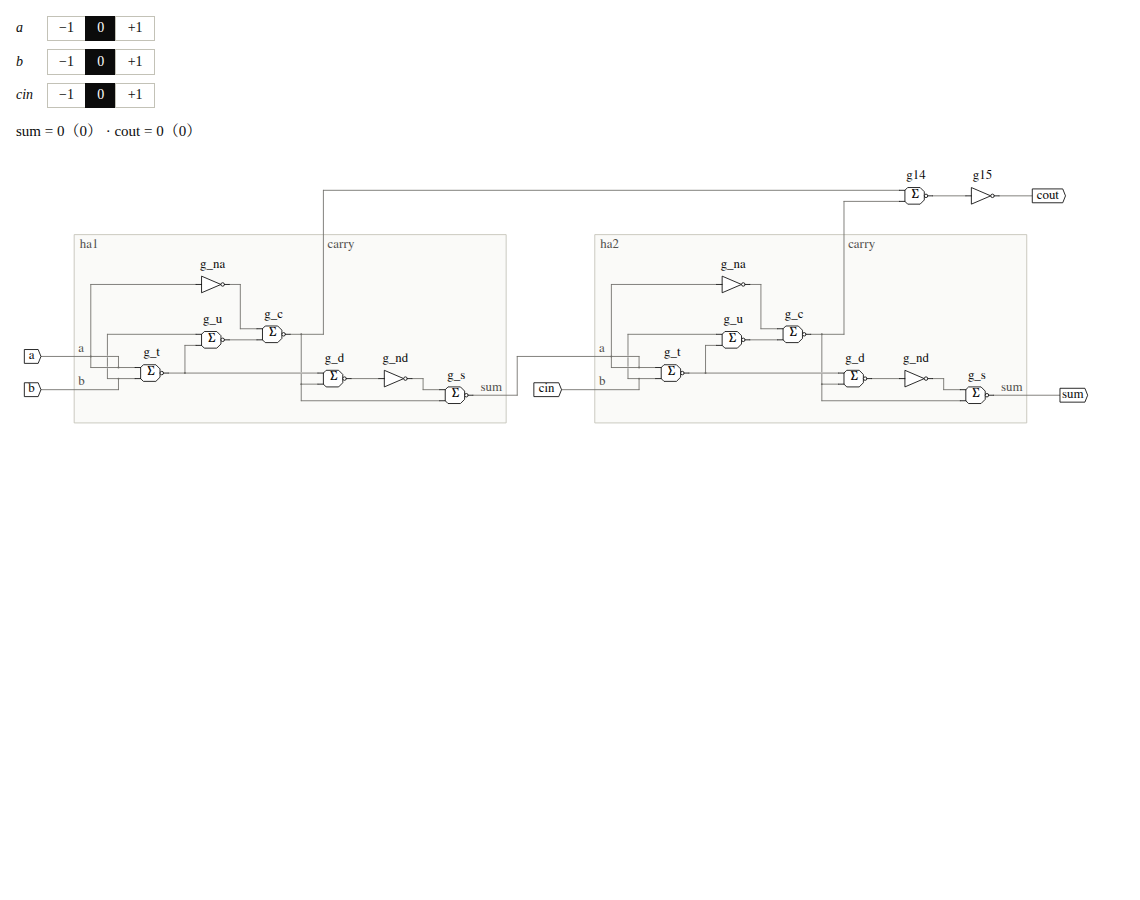

In [13]:
# 3-2 論理合成する
need("full_add_source", why="合成するHDLは、3-1に書いてあります。")
with step("論理合成") as s:
    full_add_rtl = flow.loads(full_add_source).synthesize()
    s.done(" · ".join(f"{cell}×{n}" for cell, n in full_add_rtl.report()["cells"].items())
           + f" · 全{full_add_rtl.equivalence['vectors']}入力で等価")
bus_picker(full_add_rtl)

1トリットどうしの積は−1・0・+1のいずれかで、桁上げは生じない。w = +1 なら x を、w = −1 なら x の符号を反転した値を、w = 0 なら0を出す。論理合成はHDLの `*` をテープアウトした乗算回路の構造（NAND 2個、NOR 1個、INV 1個）に展開する。

In [14]:
# 3-3 HDL：* で書いた1トリットの積
mul_source = """
module mul(input trit w, x, output trit p);
  assign p = w * x;
endmodule
"""

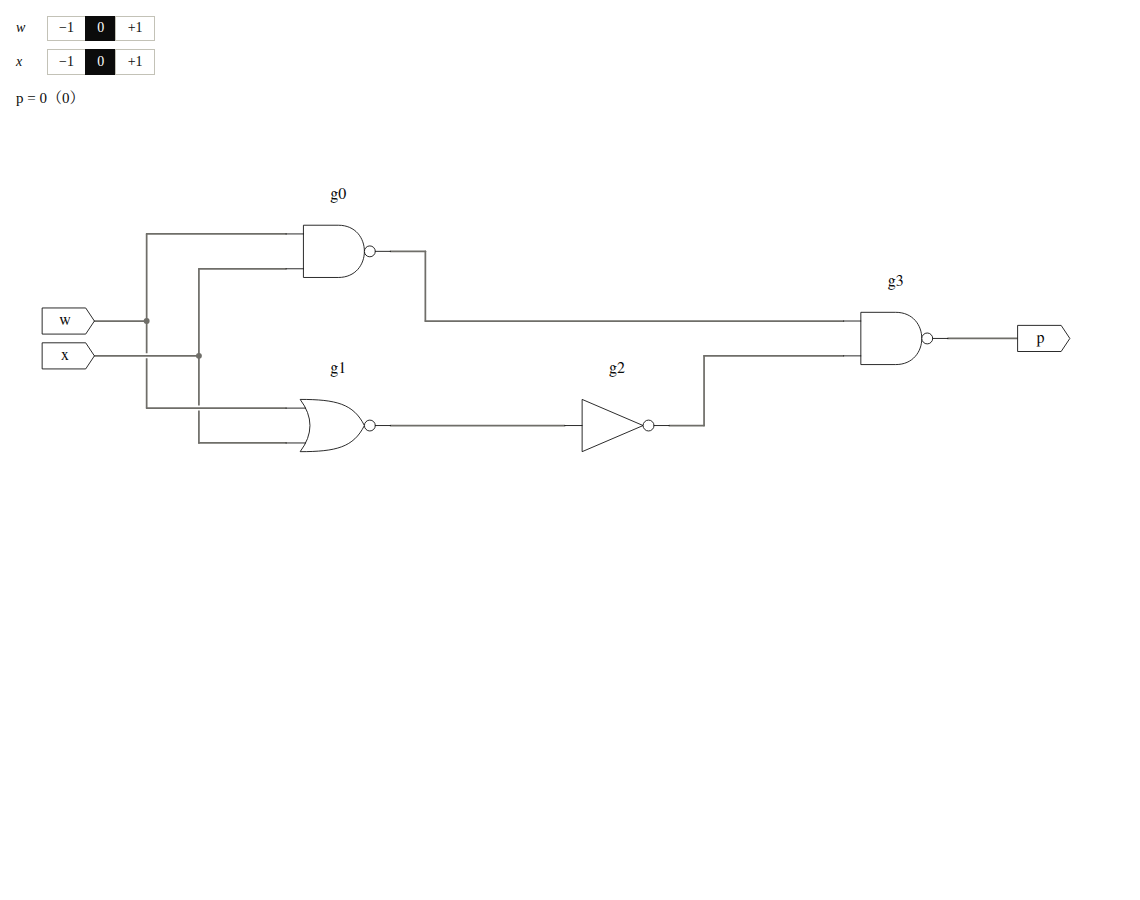

In [15]:
# 3-4 論理合成する
need("mul_source", why="合成するHDLは、3-3に書いてあります。")
with step("論理合成") as s:
    mul = flow.loads(mul_source).synthesize()
    s.done(" · ".join(f"{cell}×{n}" for cell, n in mul.report()["cells"].items())
           + f" · 全{mul.equivalence['vectors']}入力で等価")
bus_picker(mul)

### 3.5 選択：場合分けを回路にする

`if`・`case`・`?:` で書いた場合分けは、条件に応じて候補のどれか1つを出力に通す回路（選択回路）に置き換える。二値では条件が0か1なので、選択回路はANDとORで作れる。三値では条件そのものが−1・0・+1をとりうるため、条件が0のときの出力も決めておく必要がある。論理合成は、条件が0をとりうるかどうかで、2種類の選択回路を使い分ける。

例として、1トリットの入力 a、b、op から、op が +1 なら a を、−1 なら b を出力 r に出す回路を2通りに書く。

In [16]:
# 3-5 HDL：同じ選択を2通りに書く
select_sources = {
"(op == 1't1) ? a : b": """
module sel_cmp(input trit a, b, op, output trit r);
  assign r = (op == 1't1) ? a : b;
endmodule
""",
"op ? a : b": """
module sel_raw(input trit a, b, op, output trit r);
  assign r = op ? a : b;
endmodule
""",
}

1つ目は比較 `op == 1't1` を条件にしている。この比較の結果を s とすると、s は真（+1）か偽（−1）のどちらかで、0にはならない。op = 0 のときは偽なので b を選ぶ。条件が0にならなければ、出力 r は二値のANDとORによる選択と同じ形の次の式で作れる。

$$r = \max\bigl(\min(s,\ a),\ \min(-s,\ b)\bigr)$$

s = +1 なら min(s, a) は a、min(−s, b) は −1 になり、max をとると a が残る。s = −1 なら、同じように b が残る。min、max、符号反転は、NAND、NOR、INVで作れる。`case` も、ラベルとの一致を条件にすれば同じ形になる。

2つ目は op をそのまま条件にしているので、op = 0 の場合が残る。TritVerilogでは、このとき a と b が一致すればその値を、一致しなければ0を出すと定めている。多トリットの値では桁ごとに比べる。この振る舞いには条件の3つの値それぞれに対応する入力を持つ三値の選択回路（MUX3）を使う。

,BUF,INV,NAND,NANY,NOR,TIEN,TIEP,TIEZ,計,等価性の検証
(op == 1't1) ? a : b,,5,2,2,1,1,,,11,全27入力で一致
op ? a : b,1,11,6,6,5,1,1,1,32,全27入力で一致


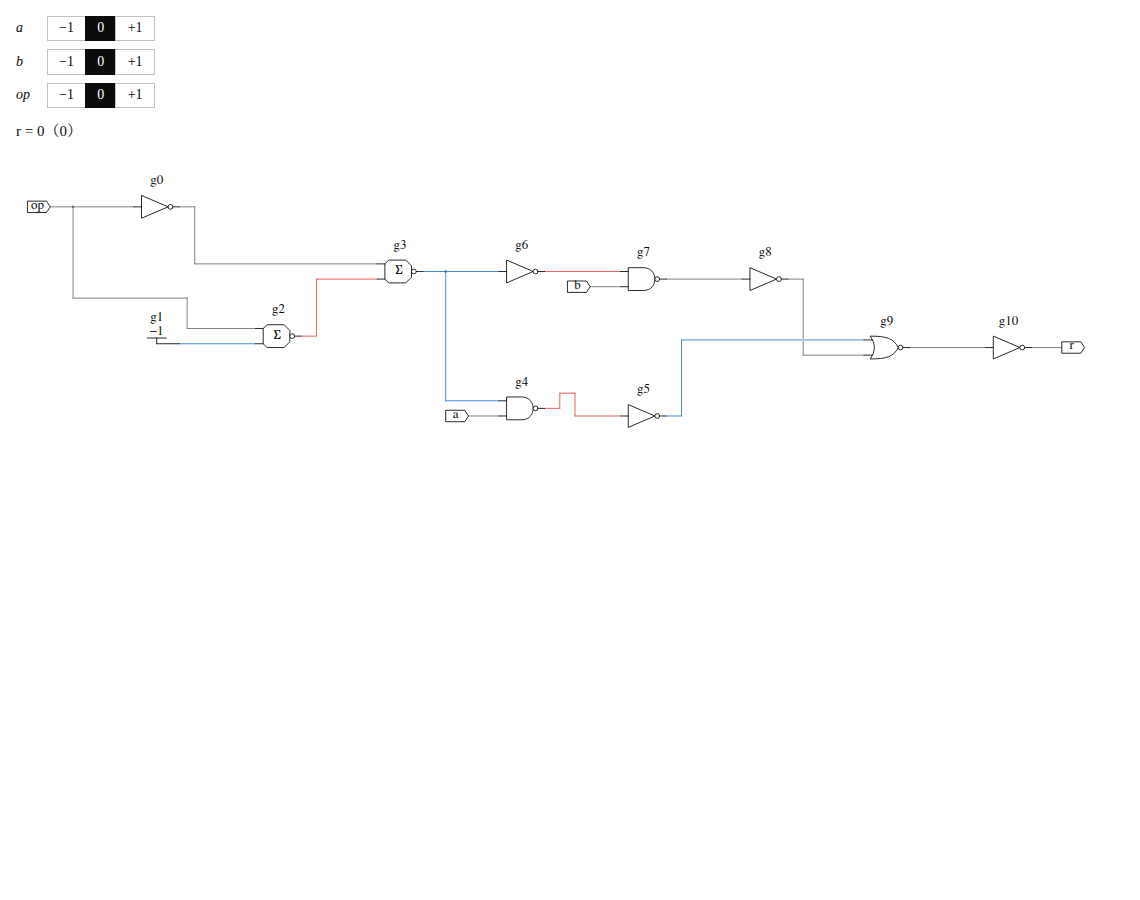

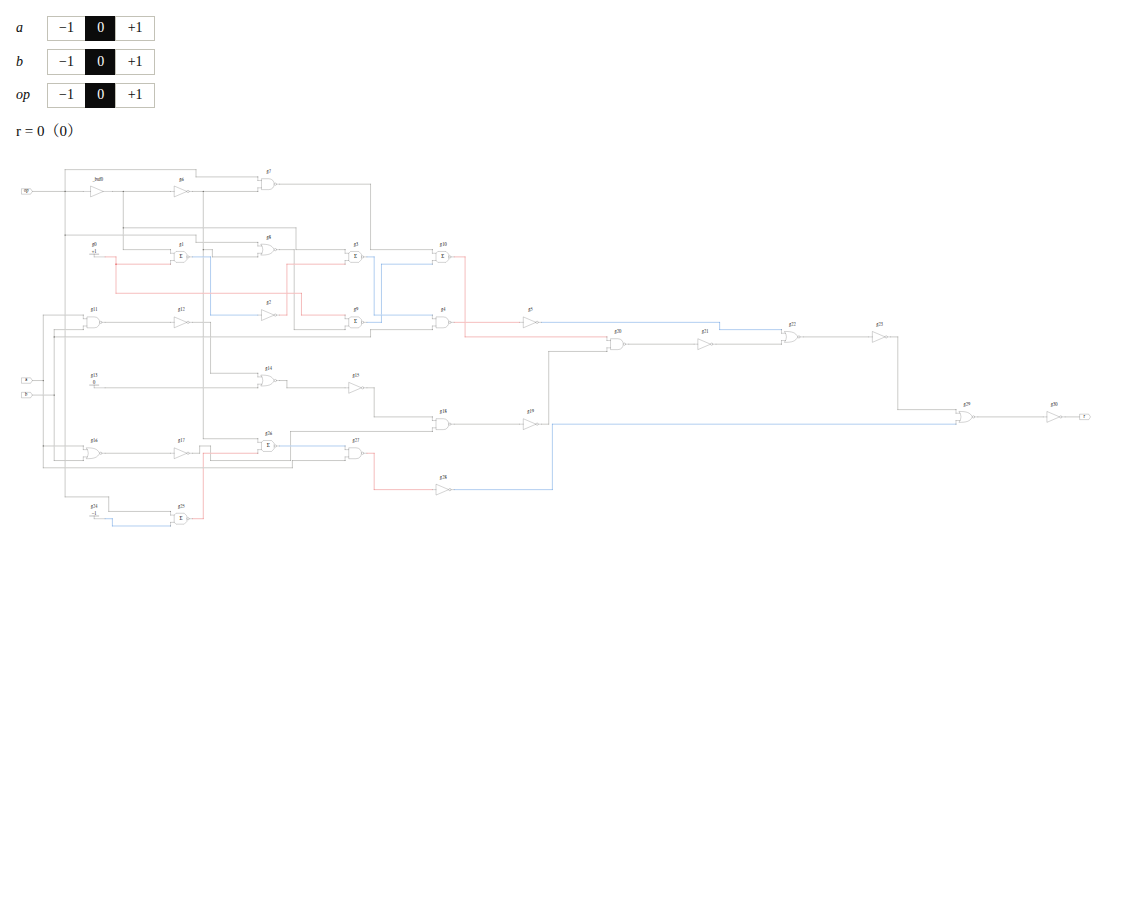

In [17]:
# 3-6 論理合成して比べる
need("select_sources", why="合成するHDLは、3-5に書いてあります。")
with step("論理合成（2通り）") as s:
    selects = {name: flow.loads(source).synthesize() for name, source in select_sources.items()}
    s.done(" · ".join(f"{name} {net.report()['total_cells']}セル" for name, net in selects.items()))
cell_counts(selects)
for net in selects.values():
    bus_picker(net)

2つ目はMUX3が要るため、1つ目より大きくなる。論理合成は、条件が0をとらないことを中間表現の上で確かめてから、1つ目の形を使う。

### 3.6 等価性の検証

論理合成は、合成した回路網がHDLと同じ関数になっていることを、合成のたびに確かめる。HDLの意味は整数と真理値表の規則で、回路網はセルの真理値表で、それぞれ別々に計算し、出力を比べる。入力が12トリット以下なら全組合せを、それより多ければ乱数で選んだ10万通りを比べる。ここまでの合成結果の「全○入力で一致」は、この検証の結果である。

### 3.7 三値重みの積和

冒頭で述べた[BitNet b1.58](https://doi.org/10.48550/arXiv.2402.17764)の行列積は、三値の重み $w_i$ と入力 $x_i$ の積和 $y = \sum_i w_i x_i$ の繰り返しである。BitNet b1.58の入力は8ビットであるが、ここでは入力も1トリットに限定する。TritFlowのセルの元になった回路も、テープアウトした1トリットの積和回路（$X + A \times B + C_{in} = S + 3\,C_{out}$）であり、この積和の1項にあたる。ここでは3.4の `*` と `+` で、4項の積和 dot4 を書く。各項の積は−1から+1、4項の和は−4から+4の範囲なので、出力 y は2トリットで表せる。

In [18]:
# 3-7 HDL：三値重みの4項の積和
dot4_source = """
module dot4(input trit w0, w1, w2, w3, x0, x1, x2, x3, output trit [1:0] y);
  assign y = w0*x0 + w1*x1 + w2*x2 + w3*x3;
endmodule
"""

In [19]:
# 3-8 論理合成する
need("dot4_source", why="合成するHDLは、3-7に書いてあります。")
with step("論理合成") as s:
    dot4 = flow.loads(dot4_source).synthesize()
    s.done(" · ".join(f"{cell}×{n}" for cell, n in dot4.report()["cells"].items())
           + f" · 全{dot4.equivalence['vectors']}入力で等価")

4つの積がそれぞれNAND 2個、NOR 1個、INV 1個になり、残りのNANYとINVは和を求める全加算器1個と半加算器2個である。4章と5章ではこのdot4を配置配線し、検証とポストレイアウトシミュレーションを行う。6章では積和の規模に対する面積・遅延・静的電力を評価し、HDLの変更とシャトル用の最上位レイアウトへの適用を示す。

## 4. 配置配線

3章で得たセルの回路網を、TR-1umの上に並べて配線し、GDSにする。題材は3.7の積和dot4である。

### 4.1 配置配線器を作った理由

配置配線は信号が二値か三値かを問わないので、原理的にはOpenROADも使える。TR-1umでもLibreLaneへの移植が試みられている（[luyanaa/TR-1um](https://github.com/luyanaa/TR-1um)、実験段階）。ただ、TR-1umで配線に使えるメタルはM1とM2の2層だけで、三値のセルはLibertyで表せず、すべてのセルに3本の電源レールを通す必要もある。そこでTritFlowはセル行の間にチャネルを空けて2層で配線する、小さな配置配線器を持つ。

### 4.2 配置：焼きなまし法

セルは横に並べた行に置き、行と行の間に配線用の通り道（チャネル）を空ける。初めに、入力に近いセルから信号の流れの順に、各セルを最も短い行へ詰めて置く。そこから焼きなまし法で改善する。1回の試行では2つのセルを入れ替える（60%）、1つのセルを別の位置や行へ移す（30%）、1つのセルを左右反転する（10%）のいずれかを行う。評価値が下がれば採用し、上がっても温度に応じた確率で採用する。温度は段が進むにつれて下げ、600段で終える。

評価値は各ネットの端子を囲む長方形の半周長の和（配線長の見積もり）に、最も長い行の幅を小さな重みで加えたものである。三値のセルは0を出す間も電流が流れ続けるため、1本の電源レールに流れる電流が許容値を超える配置は、評価値を無限大にして選ばない。

### 4.3 配線：迷路探索

配線はチャネルを横に走るM1と、セルの上を縦に走るM2の2層で引く。配線の格子の上で、各ネットの端子をA*探索でつなぐ。端子が多く広がりの大きいネットから順に引き、引けないネットが出たら、すべての配線を外し、そのネットを先頭にして残りの順を入れ替えてやり直す（最大3回）。電源は縦に走るM2の幹線から各行のレールへ供給する。

配置配線を実行する。図は実行中の配置と配線を描き、終了後は、記録した配置の途中経過とネットを引いた順をスライダーでたどる図に置き換わる。

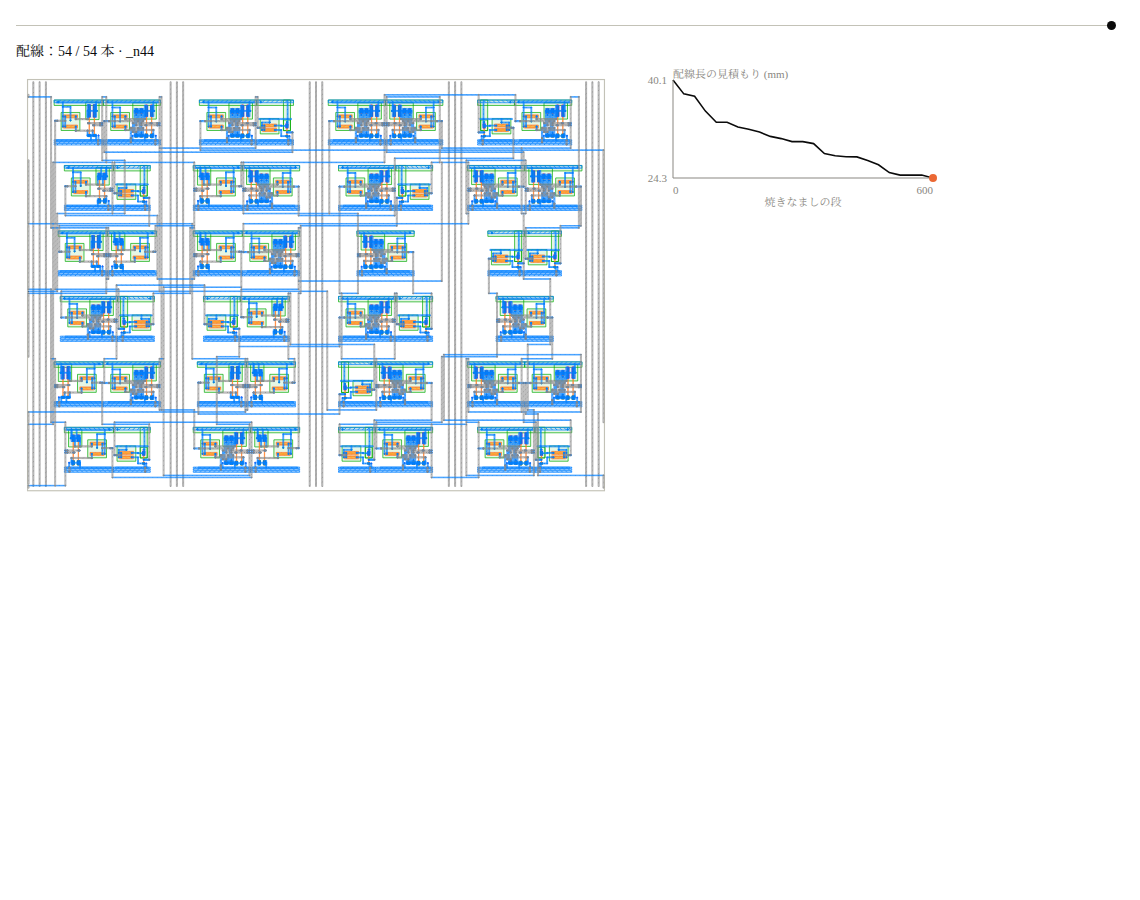

In [20]:
# 4-1 配置配線する
need("dot4", why="配置配線する回路は、3-8で合成した積和です。")
with step("配置配線", view=LayoutView()) as s:
    dot4_layout = dot4.place_and_route(output_dir=BUILD/"dot4", seed=0)
    stats = dot4_layout.stats
    s.done(f"{stats['instance_count']}セル · {stats['row_count']}行 · {stats['die_size_um'][0]:.0f} × {stats['die_size_um'][1]:.0f} µm · "
           f"配線長の見積もり {stats['hpwl_before_um']/1e3:.1f} → {stats['hpwl_after_um']/1e3:.1f} mm · ビア {stats['via_count']}個",
           picture=replay(dot4_layout))

できたGDSを示す。

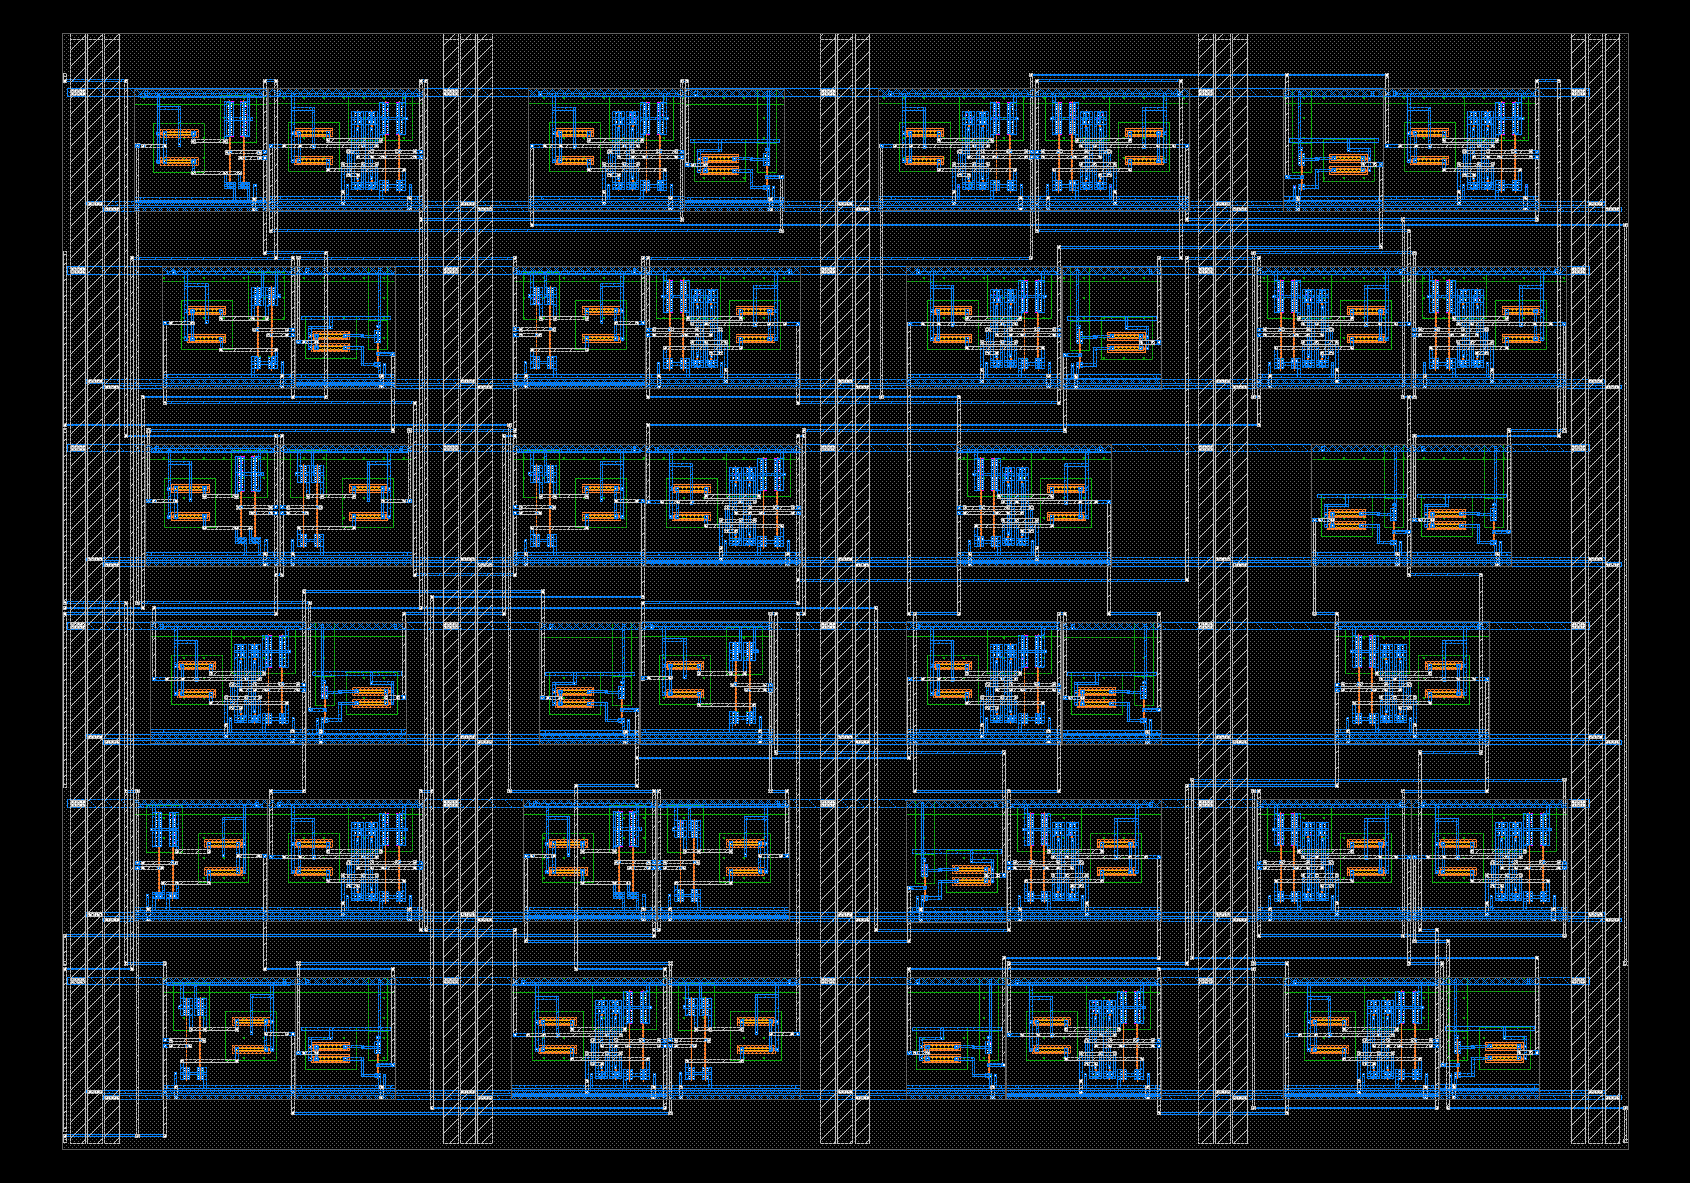

In [21]:
# 4-2 GDS
need("dot4_layout", why="表示するGDSは、4-1で作ります。")
gds_viewer(dot4_layout.gds_path)

ここまでで、セルの回路網からGDSまでを見た。次章では、このGDSをPDKのルールで検証し、ポストレイアウトシミュレーションで速さを確かめる。

## 5. 検証とタイミング

4章で作ったGDSを、PDKのルールで検証し、ポストレイアウトシミュレーションで動作と速さを確かめる。最後に、SPICEを使わずに遅延を見積もる三値のSTAを、SPICEと比べる。題材は4章と同じ積和dot4である。

### 5.1 DRCとLVS

GDSを、PDKの公式のDRCデッキとLVSデッキで検証する。LVSでは、KLayoutがGDSから素子とその接続を取り出し、合成した回路網と照合する。

In [22]:
# 5-1 DRCとLVS
need("dot4_layout", why="検証するGDSは、4-1で作ります。")
with step("DRC（PDKのデッキ）") as s:
    dot4_drc = dot4_layout.drc()
    s.done(f"違反 {dot4_drc['violations']}件")
with step("LVS（PDKのデッキ）") as s:
    dot4_lvs = dot4_layout.lvs()
    s.done("一致" if dot4_lvs["matched"] else "不一致")

### 5.2 抽出と配線容量

TR-1umのPDKには、寄生抽出（PEX）のルールがない。そこでTritFlowはLVSで一致したGDSから素子のネットリストを取り出し、各ネットのM1とM2の面積と周長から、基板との間の配線容量を見積もって加える。係数はPDKで較正した値ではなく、酸化膜の比誘電率を3.9、基板からの高さをM1で1 µm、M2で2 µm、周長あたりのフリンジ容量を0.02 fF/µmと仮定して求めた。配線どうしの結合容量と配線抵抗は含めない。

In [23]:
# 5-2 抽出と配線容量
need("dot4_lvs", why="抽出は、5-1でLVSが一致したGDSから行います。")
with step("抽出と配線容量") as s:
    dot4_extracted = dot4_layout.extract()
    dot4_wires = dot4_layout.result.net_parasitics()
    s.done(f"素子のネットリスト · 信号{len(dot4_wires['nets'])}本に配線容量を追加")
wire_table(dot4_wires)

ネット,配線容量 (fF)
_n33,227.5
y[0],204.6
_n11,170.0
x3,151.7
x1,138.8
_n9,131.1
_n30,130.6
_n8,130.4
全54ネットの合計,4157


### 5.3 三値の遅延

二値の遅延は、出力が電源電圧の半分を横切る時刻で測ることが多い。三値では電源電圧の半分が0のレベルそのものであり、−1から+1への遷移も途中で0の付近を通るため、この測り方は使えない。TritFlowは、入力が変わり始めてから、出力が新しい値の±0.5 Vの帯に入ってそのまま留まるまでの時間を遅延とする。

重みを w = (+1, −1, +1, +1) に固定し、入力 x を、和に桁上げが起きる列で変える。これは学習を終えた重みを固定して入力を流す推論と同じ使い方である。配線容量を加えたネットリストでシミュレーションし、各出力で最も遅い遷移に、遅延を矢印で示す。

論理合成の等価性検証は全6561入力を対象とする一方、このポストレイアウトSPICEは1組の固定重みに対する11区間を対象とする。

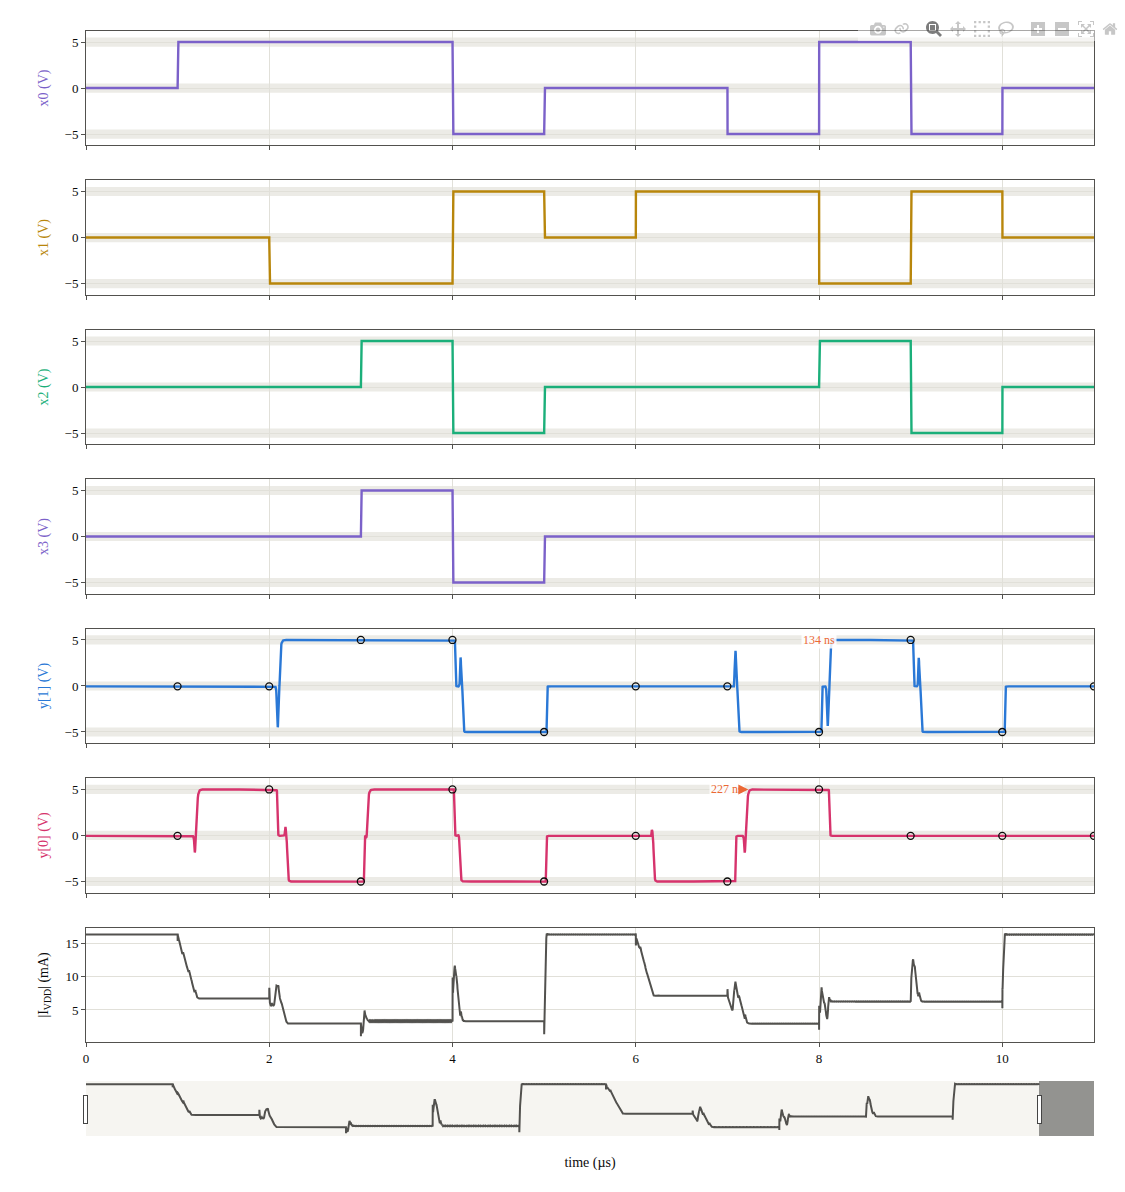

In [24]:
# 5-3 ポストレイアウトシミュレーション
need("dot4_extracted", why="シミュレーションする回路は、5-2で抽出します。")
from tritflow.sim.postlayout import logical_nodeset
dot4_inputs = [p.name for p in dot4.ports if p.dir == "input"]
weights = (+1, -1, +1, +1)
activations = [(0, 0, 0, 0), (1, 0, 0, 0), (1, -1, 0, 0), (1, -1, 1, 1), (-1, 1, -1, -1), (0, 0, 0, 0),
               (0, 1, 0, 0), (-1, 1, 0, 0), (1, -1, 1, 0), (-1, 1, -1, 0), (0, 0, 0, 0)]
def operands(x):
    """The circuit's input trits for the fixed weights and the activations x, in port order."""
    values = {f"w{i}": w for i, w in enumerate(weights)} | {f"x{i}": v for i, v in enumerate(x)}
    return tuple(values[p] for p in dot4_inputs)
dot4_vectors = [operands(x) for x in activations]
with step("ngspice") as s:
    dot4_post = dot4_extracted.simulate(dot4_vectors, load=100e-15, hold_s=1e-6, step_s=5e-9, edge_s=1e-9,
                                        temperature_c=27, timeout=600, workdir=BUILD/"dot4"/"postlayout",
                                        nodeset=logical_nodeset(dot4, dot4_lvs["report"], dot4_inputs, dot4_vectors[0]))
    s.done("全区間で ±0.5 V の帯に入った" if dot4_post["measurements"]["passed"] else "帯に入らない区間がある")
display(HTML(scope_figure(dot4_post, settle=True).to_html(include_plotlyjs="cdn", full_html=False,
                                                         config={"displaylogo": False, "scrollZoom": True})))
transient_conditions(dot4_post, load_f=100e-15)

### 5.4 三値のSTA

SPICEは正確だが時間がかかる。STA（静的タイミング解析）は回路の波形を計算する代わりに、前もって測ったセルごとの遅延を表から引き、回路を入力から出力へ順にたどって、各ネットに信号が届く時刻を求める。二値のSTAが区別する遷移は立ち上がりと立ち下がりの2種類だが、三値では−1、0、+1の間に6種類の遷移があり、セルの遅延は遷移ごとに異なる。

TritFlowの三値のSTAはセルごとに、入力の遷移の種類、入力の変化時間、負荷容量に対する伝搬遅延と出力の変化時間をSPICEで測った表を使う。伝搬遅延は、入力と出力がそれぞれ変化前と変化後のレベルの中点を横切る時刻の差である。出力の変化時間は、出力が変化の10%から90%まで進む時間で、次の段の入力の変化時間の見積もりに使う。回路の出力では、中点を横切ってから±0.5 Vの帯に入るまでの時間を足し、5.3と同じ定義の遅延にする。入力の変化時間が1 nsのときのINVの表を示す。

In [25]:
# 5-4 INVの遅延の表
delay_table("INV")

INVの入力は1本なので、表の行は6種類の遷移である。入力が2本のセルは、もう一方の入力の値ごとの表と、2本が同時に変わるときの表を持つ。5.3と同じ入力の列について、STAの見積もりとSPICEを比べる。

In [26]:
# 5-5 三値のSTAとSPICEの比較
need("dot4_post", why="比べるSPICEの結果は、5-3で求めます。")
from tritflow.sta import analyze
states = [dict(zip(dot4_inputs, v)) for v in dot4_vectors]
with step("三値のSTA") as s:
    dot4_timing = analyze(dot4, vector_pairs=list(zip(states, states[1:])),
                          wire_caps={n: e["wire_capacitance_f"] for n, e in dot4_wires["nets"].items()},
                          output_load_f=100e-15, input_transition_s=1e-9)
    s.done(f"{len(dot4_timing.arrival)}出力")
timing_table(dot4_post, dot4_timing)
note("STAの条件：5-3と同じ入力の列、出力の負荷 100 fF、入力の変化時間 1 ns、配線容量は5-2の抽出値。")

出力,SPICE (ns),STA (ns),差
y[1],133.6,120.7,−10%
y[0],227.4,219.9,−3%


ここまでで、HDLから検証済みのGDSと、その速さまでを見た。6章では積和の項数に対する面積・遅延・静的電力を評価し、HDLの変更からの再実行と、シャトル用の最上位レイアウトを示す。

## 6. 評価と応用

5章では4項の積和dot4をポストレイアウトシミュレーションで検証し、三値のSTAと比較した。本章では積和の項数を変えて面積・遅延・静的電力を評価する。続いて、HDLの変更から同じフローを実行し、シャトル用の最上位レイアウトを示す。

### 6.1 積和の規模と面積

評価する回路は1トリットの重みと入力による積和 $y = \sum_{i=0}^{N-1} w_i x_i$ である。出力の桁数は$-N$から$+N$までを表せる最小の桁数とする。重みはHDLの入力として残し、シミュレーションでは $(+1, -1, +1, +1)$ を繰り返した値に固定する。加算は3.7と同じ書き方で合成し、項数に応じた構造の変更は加えない。

各回路の配置配線と検証の記録を示す。面積は配置配線したダイの外形から求める。配線容量は5.2と同じ見積もりであり、PDKで較正された寄生抽出値ではない。記録のソース、セル、PDK、シミュレータの識別情報を照合して読み込み、再計算は明示したスイッチで切り替える。

In [27]:
# 6-1 積和の規模と面積（記録済み）
from scale_views import load_scaling, scaling_table, synthesis_table
# 全掃引は長時間かかる（N=16の解析とN=32の配置配線試行を含む）。
RECOMPUTE_SCALING = False #@param {type:"boolean"}
dot_scaling = load_scaling(recompute=RECOMPUTE_SCALING)
display(synthesis_table(dot_scaling), scaling_table(dot_scaling))
for attempt in dot_scaling.get("optional_attempts", []):
    stage = "配置配線が未完了" if not attempt.get("pnr") else "検証が未完了"
    note(f"追加試行 N={attempt['n']} は{stage}のため、以下の比較には含めない。")
for row in dot_scaling["rows"]:
    options = row["conditions"].get("pnr_options", {})
    if options:
        note(f"N={row['n']}で既定値から変更した配置配線条件："
             f"行間チャネルの配線トラック {options['channel_tracks']}本、"
             f"M1の幅1 µm当たりの許容電流 {options['current_density_a_per_um']*1e3:g} mA。")
conditions = dot_scaling["conditions"]
holds = "、".join(f"N={row['n']}: {row['conditions']['hold_s']*1e6:g} µs"
                  for row in dot_scaling["rows"])
note(f"記録の条件：ngspice-{dot_scaling['provenance']['simulator']['version']}、"
     f"PDK {dot_scaling['provenance']['pdk']['qualified_commit'][:7]}、"
     f"{conditions['temperature_c']:g} °C、電源 +5 / 0 / −5 V。"
     f"出力負荷 {conditions['load_f']*1e15:g} fF、入力の変化時間 {conditions['edge_s']*1e9:g} ns、"
     f"最大時間刻み {conditions['step_s']*1e9:g} ns。各状態の保持時間は {holds}。")

項数 N,出力桁数,INV,NAND,NANY,NOR,検証入力数,等価性
2,2,4,4,5,2,全入力 81,等価
4,2,13,8,21,4,"全入力 6,561",等価
8,3,35,16,63,8,"乱数 100,000",等価
16,4,92,32,175,16,"乱数 100,000",等価


項数 N,セル数,ダイ寸法mm × mm,ダイ面積mm²,行数,HPWLmm,実配線長mm,信号ビア,配置配線s,DRC / LVS
2,15,0.61 × 0.87,0.53,5,3.95,8.27,107,1.73,0 / 一致
4,46,1.69 × 1.21,2.04,6,24.30,40.44,329,2.98,0 / 一致
8,122,2.16 × 3.05,6.60,13,167.86,236.37,1146,35.99,0 / 一致
16,315,5.51 × 3.89,21.45,13,832.90,"1,230.38",3320,48.55,0 / 一致


項数が増えると積の回路だけでなく、和を表す桁数に応じて加算回路も増える。ダイ面積にはこれらのセルに加えて電源と信号の配線領域が含まれるため、項数だけに比例する面積増加にはならない。

### 6.2 静的電力と時間平均

抵抗分圧によって0 Vを保つ状態では、入力を切り替えなくても静的電流が流れる。NANYにはVDD・VSS側の直列MOS経路を遮断し、VMIDへのクランプで0 Vを出す状態もある。静的電力は記録した入力列に含まれる状態のDC動作点から求める。SPICEの電圧源に流れ込む向きを電流の正とすると、回路が消費する電力は $P = -\sum_r V_r I_r$ であり、正負両方の電源の寄与を含む。

時間平均の供給電力は入力列の全保持区間にわたって電力波形を積分し、全時間で除して求める。この値には入力状態ごとに異なる静的消費と遷移時の消費が含まれ、スイッチングのみのエネルギーには分離していない。入力を駆動する電圧源の電力は含めない。

項数 N,セル数,|I(VDD)|mA・x=0,|I(VSS)|mA・x=0,静的電力mW・x=0,時間平均mW,静的/セルmW・x=0,平均/セルmW,DCの範囲mW,保持時間µs/区間
2,15,5.04,5.04,50.41,21.72,3.361,1.448,4.07–50.41,1.00
4,46,16.35,16.35,163.48,85.80,3.554,1.865,29.51–163.48,1.00
8,122,45.21,45.21,452.08,229.51,3.706,1.881,86.92–452.08,1.00
16,315,120.02,120.02,"1,200.19",638.63,3.810,2.027,"336.76–1,200.19",1.25


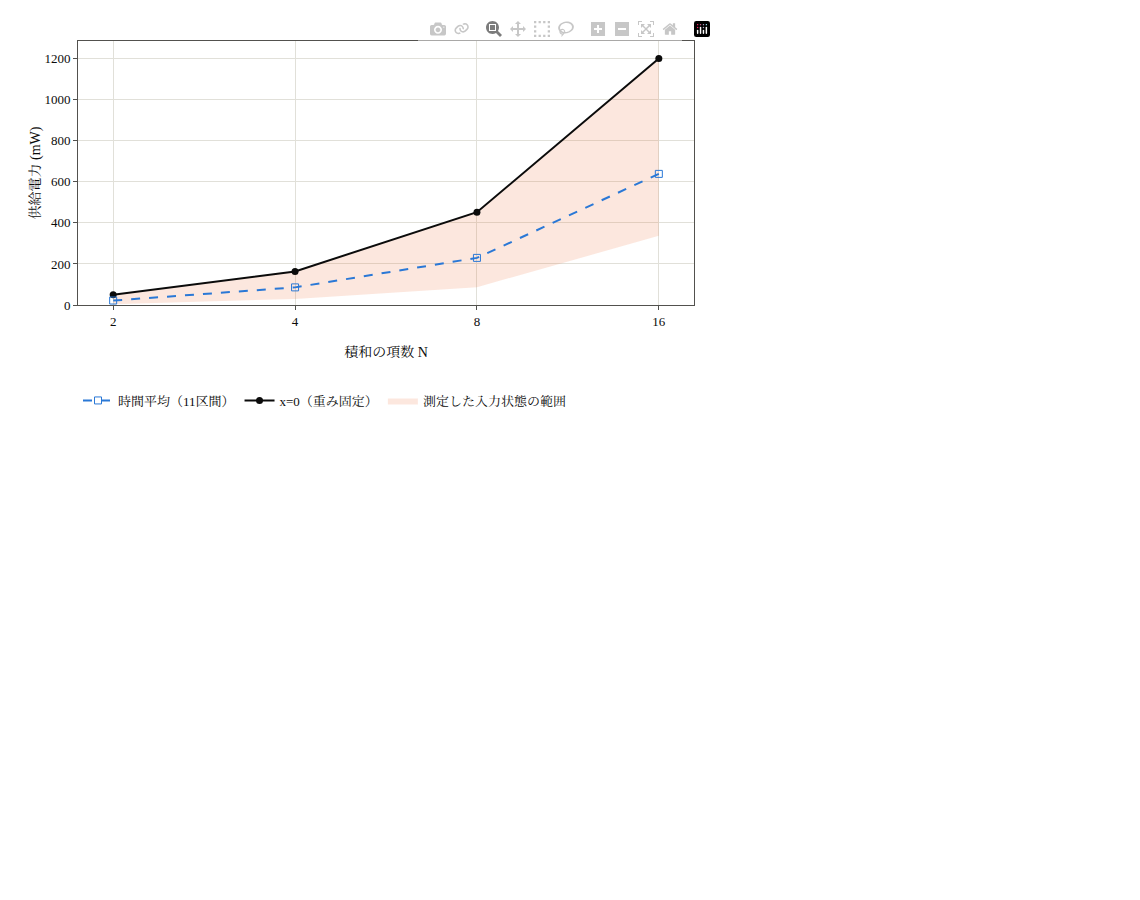

In [28]:
# 6-2 静的電流と電力（記録済み）
need("dot_scaling", why="表示する記録は、6-1で読み込みます。")
from scale_views import power_table, power_figure
power_plot = power_figure(dot_scaling)
power_plot.update_yaxes(title_text="供給電力 (mW)")
display(power_table(dot_scaling), power_plot)

入力状態によって導通する分圧回路の数が変わるため、同じ項数でも静的電力が変わる。時間平均は保持時間と入力列に依存する。これらは三値の回路を実装したときの面積・遅延・電力であり、二値の実装に対する優位性を示す比較ではない。

### 6.3 STAとSPICE

各回路で、正負の桁上げの発生と解消を含む入力の列を用いる。4項の入力列は5章とは異なる。固定した重みの条件の下でSTAを行い、STAとSPICEには同じ入力遷移、出力負荷、入力の変化時間、配線容量を与える。比較する遅延はその列で得られた出力ごとの最大整定時間である。すべての入力遷移に対する最悪値を保証するものではない。

配線容量の影響は同じ抽出回路について推定した配線容量だけを除いた場合と比較する。STAは各規模で、SPICEは4項で比較し、素子の寄生容量と100 fFの出力負荷は両方に含める。

16項では一部のNANYの負荷容量が特性表の上限2 pFを超え、最大2.862 pFとなるため、STAは負荷容量に対して線形に外挿する。

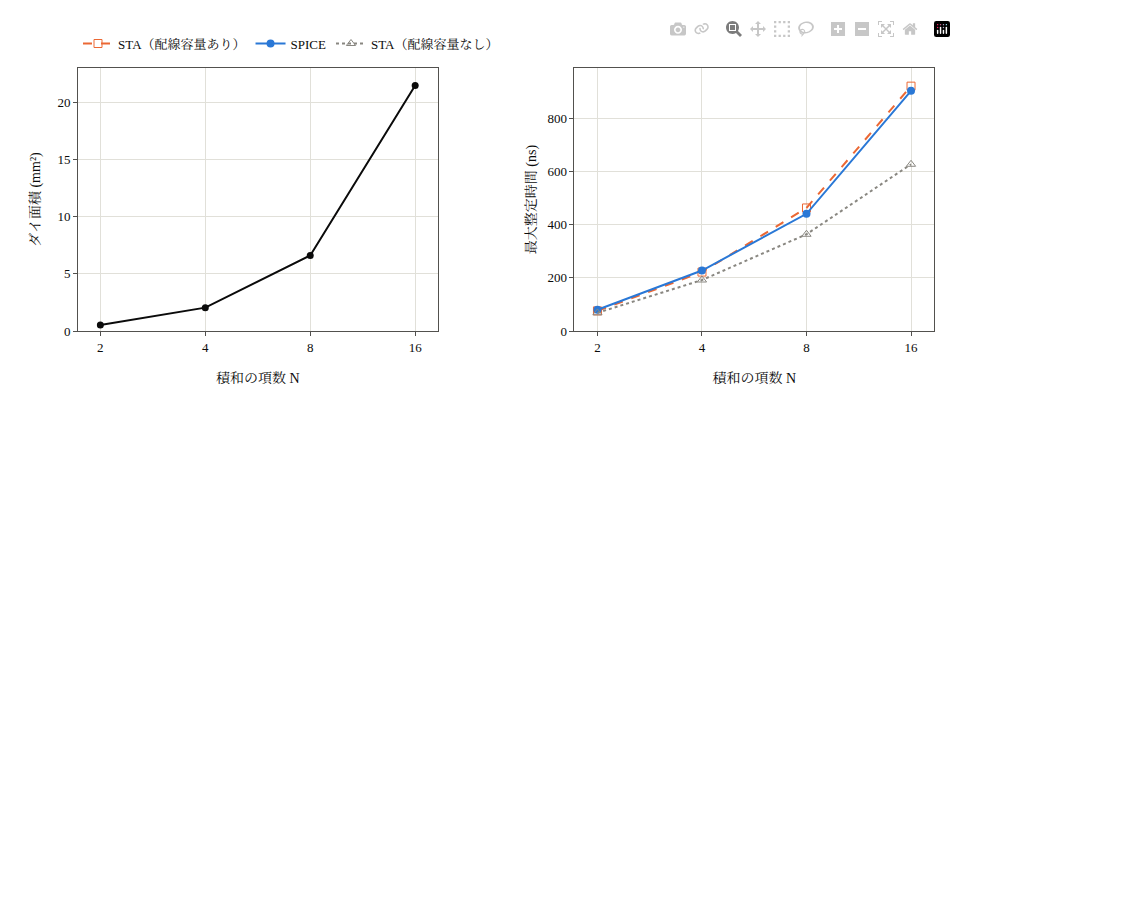

N,出力,STA・配線容量なしns,STA・配線容量ありns,増加率%,SPICE・配線容量なしns,SPICE・配線容量ありns,増加率%,STAの誤差%
2,y[1],56.2,62.9,11.9,—,80.0,—,-21.3
2,y[0],68.1,75.6,11.0,—,79.7,—,-5.0
4,y[1],106.1,122.5,15.4,113.1,128.6,13.7,-4.8
4,y[0],191.5,221.3,15.5,199.7,227.2,13.8,-2.6
8,y[2],363.3,462.2,27.2,—,432.3,—,6.9
8,y[1],333.9,422.3,26.5,—,397.0,—,6.4
8,y[0],348.3,437.0,25.5,—,440.2,—,-0.7
16,y[3],626.3,919.7,46.9,—,902.2,—,1.9
16,y[2],596.9,880.5,47.5,—,868.6,—,1.4
16,y[1],567.9,835.0,47.0,—,828.9,—,0.7


In [29]:
# 6-3 STAとSPICE（記録済み）
need("dot_scaling", why="比較する記録は、6-1で読み込みます。")
from scale_views import scaling_figure, layout_penalty_table
display(scaling_figure(dot_scaling), layout_penalty_table(dot_scaling))

5章のdot4ではSTAがSPICEよりy[1]で約10%、y[0]で約3%短い。項数を変えた比較では、規模と出力によって誤差の符号も変わる。STAは指定した入力遷移に対応するセルの特性表を使う見積もりであり、途中のグリッチを含むアナログ波形全体を計算していない。SPICEではグリッチ後に判定帯へ再び入るまでの時間も整定時間に含まれるため、STAを遅延の上界として扱うことはできない。

### 6.4 HDLの変更と再実行

推論時の重みをHDLの定数にすると、重みに応じた乗算回路が論理合成で簡単化される。次の回路はdot4の重みを $(+1, -1, +1, +1)$ に固定したものである。式と入出力の宣言を変更しても、論理合成からポストレイアウトシミュレーションまでを同じセルで実行できる。

In [30]:
# 6-4 HDLを変更する
reuse_source = """
module dot4_fixed(input trit x0, x1, x2, x3, output trit [1:0] y);
  assign y = x0 - x1 + x2 + x3;
endmodule
"""

SPICEの入力は、全状態数が27以下なら全状態、それ以外はゼロ入力、全入力が−1または+1の状態、符号が交互になる状態、1入力だけが±1の状態から11状態を選ぶ。標本による検証は全入力状態や全入力遷移を検証したことを意味しない。出力の期待値は合成した回路網からではなく、HDLの評価から求める。

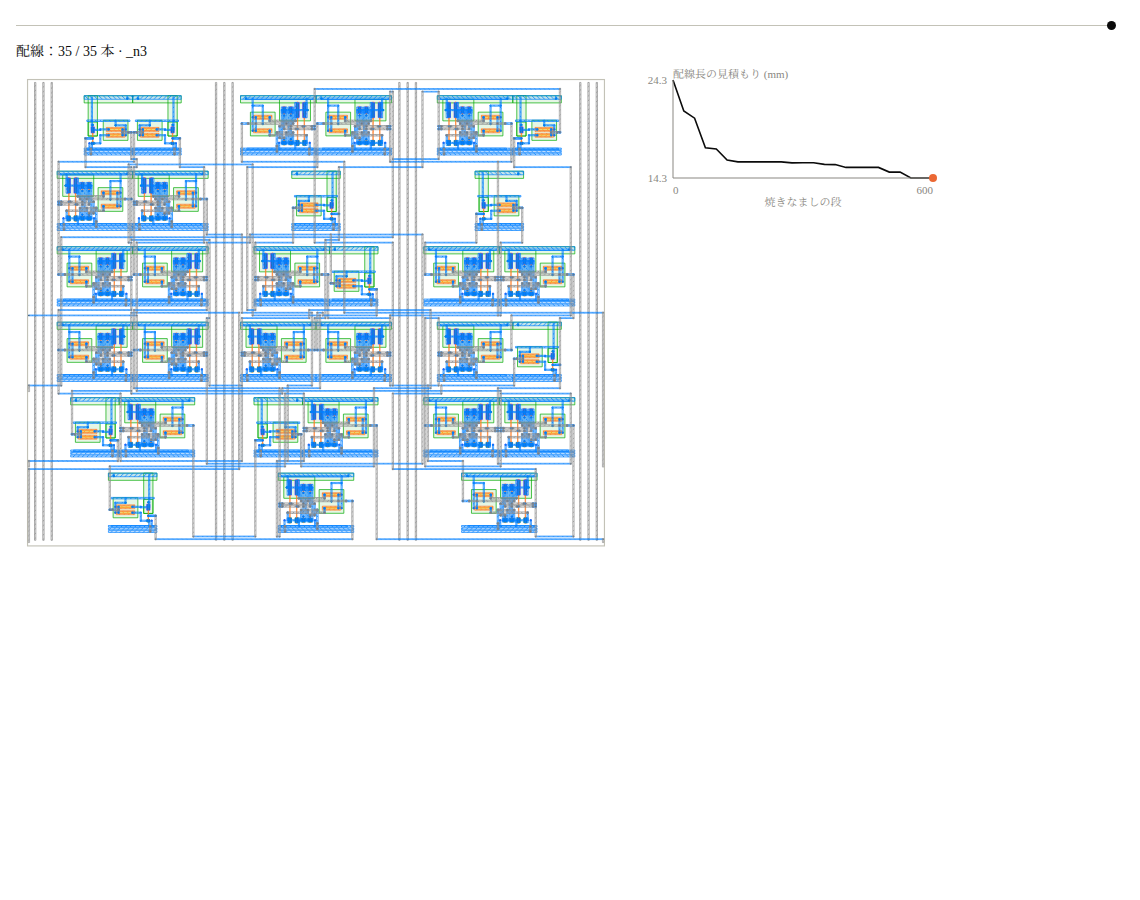

項目,結果
回路,dot4_fixed
セル数,31
マクロ寸法 (µm),1284 × 1038
DRC 違反,0
LVS,一致
SPICE 入力状態,11 / 81 (sampled states)
出力レベル・整定,PASS
最大出力誤差 (V),0.0418
y[1] 最大整定時間 (ns),167.9
y[0] 最大整定時間 (ns),218.0


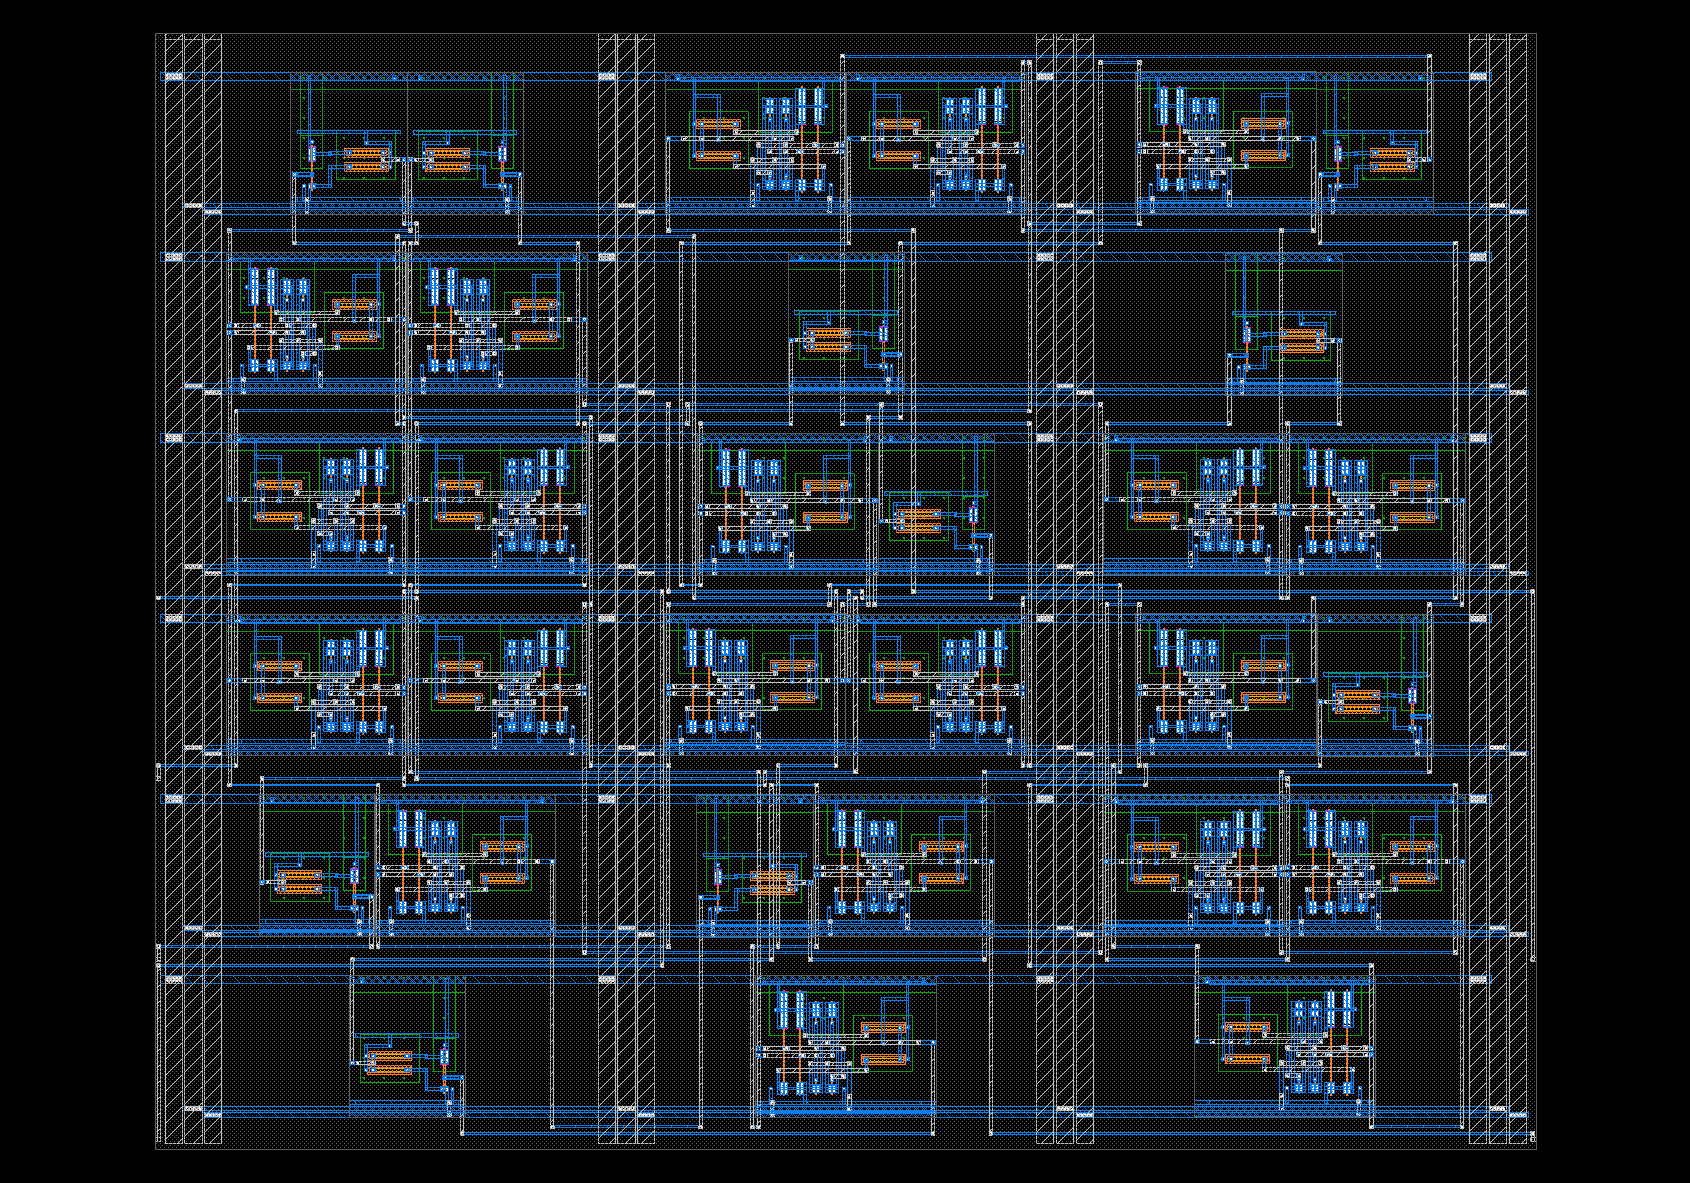

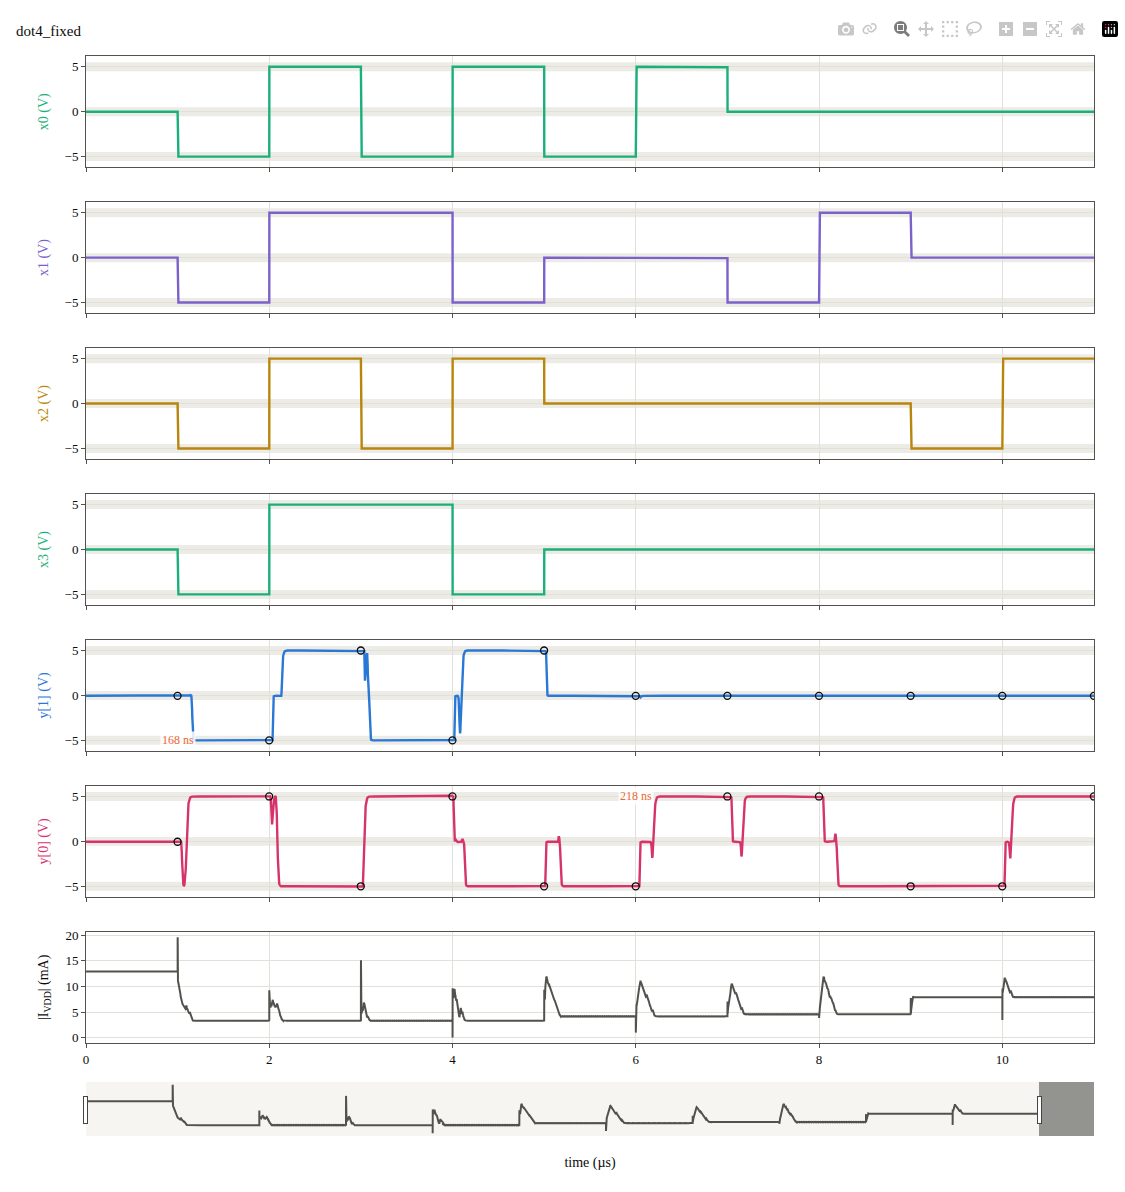

In [31]:
# 6-5 変更したHDLから全工程を実行する
need("reuse_source", why="実行するHDLは、6-4に書いてあります。")
from reuse import run
reuse_result = run(reuse_source, output_dir=BUILD/"reuse", step_s=5e-9,
                   exhaustive_limit=27, sample_size=11)

### 6.5 シャトル用の最上位レイアウト

dot4に、プローブ用パッド、電源配線、PDKのMPWフレームを付けた最上位レイアウトを示す。これは3〜5章で扱った重みを入力に持つdot4であり、6.4の定数重みの回路とは別である。カスタムのプローブ用パッド配置を用いるため、シャトル運営者によるパッド配置・パッケージ・ESD（静電気放電）・電源条件の承認を必要とする。

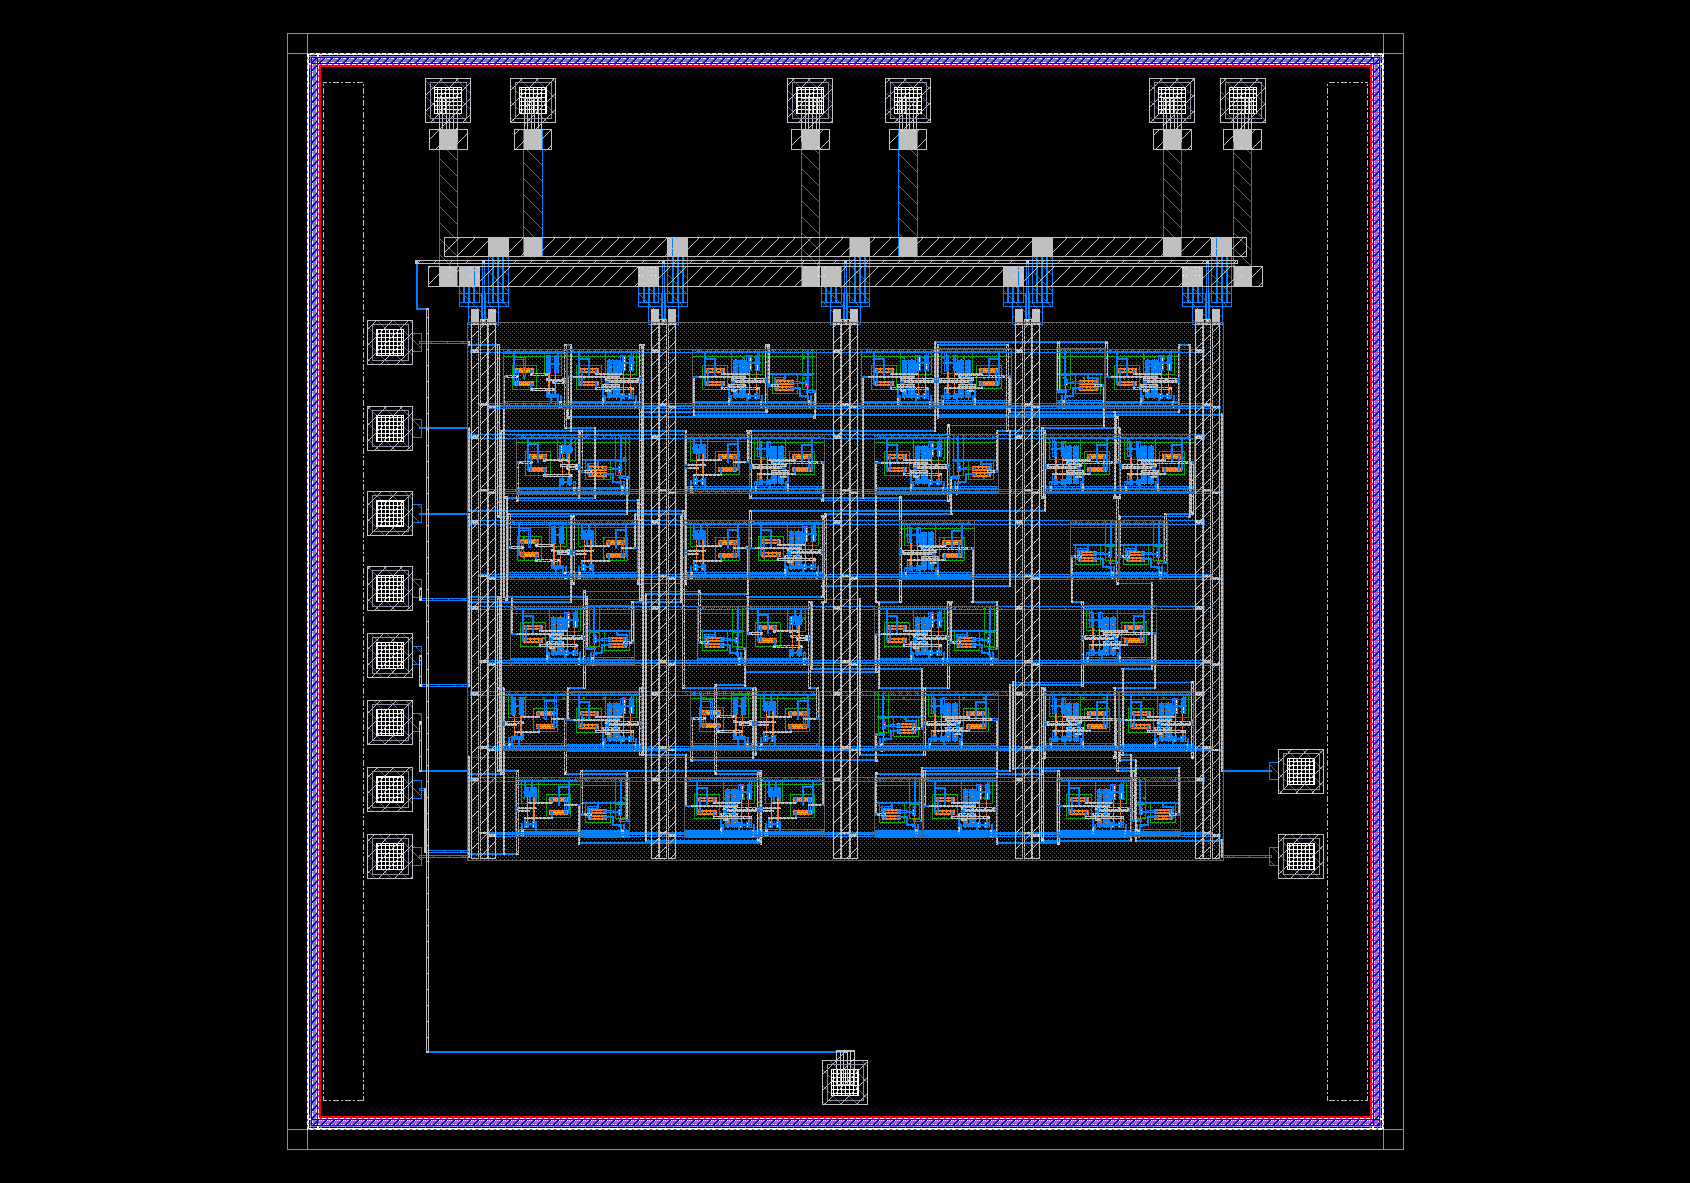

検査（記録済み）,結果
Drawing DRC 違反,0
Drawing LVS,一致
Mask DRC 違反,0
MPW precheck,PASS
Submission ready,False


Pad,信号 / 電源,方向,X (µm),Y (µm)
P01,VDD,power,-890.0,1100.0
P02,VDD,power,-78.0,1100.0
P03,VDD,power,890.0,1100.0
P04,VSS,power,-700.0,1100.0
P05,VSS,power,140.0,1100.0
P06,VSS,power,732.0,1100.0
P07,VMID,power,0.0,-1100.0
P08,w0,input,-1020.0,-594.0
P09,x3,input,-1020.0,-444.0
P10,w1,input,-1020.0,-294.0


In [32]:
# 6-6 MPWフレームとパッドを付けたdot4（記録済み）
from reuse import shuttle_view
dot4_chip = shuttle_view(ROOT/"notebook/assets/chip/dot4")

### 6.6 結論

TritFlowは平衡三値のHDLから、三つの電圧レベルを扱うセルの回路網、配置配線、PDKのDRC/LVS、ポストレイアウトシミュレーションまでを接続する。この2層配線の実装では、面積と整定時間は項数より速く増加する。静的電力は抵抗分圧による0 Vの維持で決まるため、実用的な効率を得るには0 Vを保持する別の方式が必要である。今後はテープアウトしたセルの実測とモデルの照合を行い、その結果をセルと設計フローに反映する。

### 参考文献

1. Shuming Ma et al., “The Era of 1-bit LLMs: All Large Language Models are in 1.58 Bits,” arXiv:2402.17764, 2024. [doi:10.48550/arXiv.2402.17764](https://doi.org/10.48550/arXiv.2402.17764).
2. Sheng Lin, Yong-Bin Kim, and Fabrizio Lombardi, “CNTFET-Based Design of Ternary Logic Gates and Arithmetic Circuits,” *IEEE Transactions on Nanotechnology*, 10(2), pp. 217–225, 2011. [doi:10.1109/TNANO.2009.2036845](https://doi.org/10.1109/TNANO.2009.2036845).
3. Muhammad Khalid and Jawar Singh, “Memristor based unbalanced ternary logic gates,” *Analog Integrated Circuits and Signal Processing*, 87(3), pp. 399–406, 2016. [doi:10.1007/s10470-016-0733-1](https://doi.org/10.1007/s10470-016-0733-1).
4. Xiaoyuan Wang et al., “High-Density Memristor-CMOS Ternary Logic Family,” *IEEE Transactions on Circuits and Systems I: Regular Papers*, 68(1), pp. 264–274, 2021. [doi:10.1109/TCSI.2020.3027693](https://doi.org/10.1109/TCSI.2020.3027693).
5. Jae Won Jeong et al., “Tunnelling-based ternary metal–oxide–semiconductor technology,” *Nature Electronics*, 2(7), pp. 307–312, 2019. [doi:10.1038/s41928-019-0272-8](https://doi.org/10.1038/s41928-019-0272-8).
6. Hanmok Park, Seonghoon Kim, Sunmean Kim, and Taigon Song, “An RTL-Based General Synthesis Methodology for Device-Independent Ternary Logic Circuits,” *IEEE Access*, 13, pp. 163648–163660, 2025. [doi:10.1109/ACCESS.2025.3597293](https://doi.org/10.1109/ACCESS.2025.3597293).
7. Steven Bos and contributors, *MixedRadixCircuitSynthesis (MRCS)*, source snapshot `0865cee`, 2023. [Repository](https://github.com/aiunderstand/MixedRadixCircuitSynthesis/tree/0865cee1f49fe9a803b4910b570f4e96e514c61b).
8. Mohnish Pai, “Ankhdjet: An Open-Source Compiler for Mask-Programmed Ternary Compute-in-ROM on an Open PDK,” arXiv:2608.26206, 2026. [doi:10.48550/arXiv.2608.26206](https://doi.org/10.48550/arXiv.2608.26206).
9. Jerzy Słupecki, “Kryterium pełności wielowartościowych systemów logiki zdań,” *Comptes Rendus des Séances de la Société des Sciences et des Lettres de Varsovie, Classe III*, 32, pp. 102–109, 1939. [原文](https://rcin.org.pl/Content/50652/PDF/WA35_4821_cz167-r1939-t32_Spraw-TNW-wIII-art1.pdf#page=110).
10. Jean W. Butler, “On complete and independent sets of operations in finite algebras,” *Pacific Journal of Mathematics*, 10(4), pp. 1169–1179, 1960. [本文](https://msp.org/pjm/1960/10-4/pjm-v10-n4-p10-s.pdf).
11. Stephen Cole Kleene, *Introduction to Metamathematics*, North-Holland / P. Noordhoff, 1952, §64. [書誌情報](https://cir.nii.ac.jp/crid/1971712334708500134).
12. Francesco Paoli and Gavin St. John, “Editorial Introduction,” *Studia Logica*, 112, pp. 1201–1214, 2024. [doi:10.1007/s11225-024-10147-9](https://doi.org/10.1007/s11225-024-10147-9).
13. OpenSUSI, Tokai Rika, and contributors, *TR-1um Open Source PDK project*, commit `5d963db`, 2026. [使用したPDK](https://github.com/OpenSUSI/TR-1um/tree/5d963db9d44e192d37a0489c208bfccf2e2f690c).
14. Robin Lu and contributors, *TR-1um: an experiment to port TR-1um and OpenSUSI MPW template to LibreLane + ALIGN*, source snapshot `b14b3f5`, 2026. [Repository](https://github.com/luyanaa/TR-1um/tree/b14b3f5cca671fd86804e3cca434a0a728c73642).
15. Einosuke Okazaki, *平衡3値論理回路 — OpenSUSI TR-1um (opensusi-tr10-balanced-ternary-logic)*, source snapshot `8a60b97`, 2026. [元の回路と提出資料](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic/tree/8a60b97868cad008ff21fefca5da13dcd06063f8).
16. 一般社団法人OpenSUSI, “OpenSUSI-MPW第1回募集を完了 — 企業・大学・高専・高校・個人から49枠の申し込み,” 2026年10月16日. [発表](https://prtimes.jp/main/html/rd/p/000000014.000182004.html).
17. Matthias Köfferlein and the KLayout contributors, *KLayout Layout Viewer and Editor*, version 0.30.6, 2026. [Release](https://github.com/KLayout/klayout/releases/tag/v0.30.6).
18. Holger Vogt, Giles Atkinson, and Paolo Nenzi, *Ngspice User's Manual*, version 42, 2023. [Manual](https://sourceforge.net/projects/ngspice/files/ng-spice-rework/old-releases/42/ngspice-42-manual.pdf/download).
19. ISHI会, “2025年12月イベント「東海理化シャトルのオープンPDK解説会」の参加者募集,” 2025年10月30日. [発表](https://ishi-kai.org/information/seminar/2025/10/30/DecEvent_1213.html).
20. Zane Hambly, *Takahe*, source snapshot `e7123ea`, 2026. [二値で符号化したSKY130の例](https://github.com/Zaneham/takahe/blob/e7123ea60269922acb283d576678a3aabe51f4f4/designs/setun70_physical.sv).

In [33]:
import importlib.metadata as _metadata
import json as _json
import platform as _platform
import subprocess as _subprocess
from IPython.display import display as _display

def _submission_evidence(namespace):
    """Record logic coverage, routed dimensions and nominal analog checks."""
    result = {"schema_version": 1, "designs": {}}
    for name, label in (("net", "first"), ("full_add_rtl", "full_add"),
                        ("mul", "mul"), ("dot4", "dot4")):
        circuit = namespace.get(name)
        if circuit is None:
            continue
        row = {"report": circuit.report(), "equivalence": dict(circuit.equivalence)}
        layout = namespace.get("dot4_layout" if name == "dot4" else "lay") if name in ("net", "dot4") else None
        if layout is not None:
            row["layout"] = dict(layout.stats)
            for key, variable in (("drc", "dot4_drc" if name == "dot4" else "drc"),
                                  ("lvs", "dot4_lvs" if name == "dot4" else "lvs")):
                check = namespace.get(variable)
                if check is not None:
                    row[key] = {k: check[k] for k in
                                ("clean", "violations", "matched", "strict_ports", "scope")
                                if k in check}
            post = namespace.get("dot4_post" if name == "dot4" else "post")
            if post is not None:
                row["measurements"] = post["measurements"]
                row["stimulus"] = post["stimulus"]
        if name == "dot4" and "dot4_timing" in namespace:
            row["sta_arrival_s"] = dict(namespace["dot4_timing"].arrival)
        result["designs"][label] = row
    # An optional future chapter can provide an explicit summary. Its rendered
    # tables are independently retained by the builder even without this key.
    if "submission_results" in namespace:
        result["evaluation"] = namespace["submission_results"]
    result["runtime"] = {"python": _platform.python_version(), "packages": {}}
    for package in ("numpy", "scipy", "plotly", "klayout", "lark", "matplotlib"):
        result["runtime"]["packages"][package] = _metadata.version(package)
    result["runtime"]["tools"] = namespace.get("tools", {})
    from tritflow import PDK_ROOT as _pdk_root
    from tritflow.sim.provenance import pdk_provenance as _pdk_provenance
    result["pdk"] = _pdk_provenance(_pdk_root)
    result["source_ref"] = namespace.get("SOURCE_REF")
    result["runtime_commit_at_end"] = _subprocess.check_output(
        ["git", "-C", str(namespace["ROOT"]), "rev-parse", "HEAD"], text=True).strip()
    result["runtime_commit"] = namespace.get("_submission_runtime_commit_at_start", result["runtime_commit_at_end"])
    result["tracked_working_changes_at_execution"] = _subprocess.check_output(
        ["git", "-C", str(namespace["ROOT"]), "diff", "--name-only", "HEAD"], text=True).splitlines()
    result["untracked_runtime_sources_at_execution"] = _subprocess.check_output(
        ["git", "-C", str(namespace["ROOT"]), "ls-files", "--others", "--exclude-standard",
         "tritflow", "notebook", "cells", "examples", "results"], text=True).splitlines()
    # Reject NaN/Infinity: a failed measurement must never become a result.
    return _json.loads(_json.dumps(result, allow_nan=False, default=str))

_display({"application/json": _submission_evidence(globals()),
          "text/plain": "Submission evidence: executed logic, layout, verification and timing results."}, raw=True)

Submission evidence: executed logic, layout, verification and timing results.

## Submission references and reuse

- [TritFlow source](https://github.com/PenguinEino/tritflow).
- [OpenSUSI TR-1um PDK](https://github.com/OpenSUSI/TR-1um).
- [Author's taped-out balanced-ternary cells and 1-trit multiply-add](https://github.com/PenguinEino/opensusi-tr10-balanced-ternary-logic).
- [KLayout](https://www.klayout.de/), [ngspice](https://ngspice.sourceforge.io/), [Plotly](https://plotly.com/python/), [Lark](https://github.com/lark-parser/lark).

Earlier Code-a-Chip notebooks were consulted for presentation and packaging; no notebook cells or code were copied from those submissions. The complete notebook bibliography, when present, remains in the original chapter cells.

Saved images are actual captured initial views. Re-execute the unchanged source cells for controls and animation. Pinned Markdown images are embedded for offline reading. Machine paths in outputs are normalized; numerical data is unchanged.

<details><summary>Capture and source provenance</summary>

Immutable source commit `8f77584a7d39be94b475fb4f2ddfc9be4a9ea190` matches the packaged notebook, allowing its commit-stamp line (local git-object check).

This package records local execution of v3; historical v1 Colab evidence is not promoted to v3.

Pinned bootstrap commit: `28b0f02a3e38ed5a9b81c9c6d9710d9a611275b7`. Observed execution commit: `28b0f02a3e38ed5a9b81c9c6d9710d9a611275b7`.

```json
{
  "python": "3.12.3",
  "packages": {
    "numpy": "2.4.3",
    "scipy": "1.17.1",
    "plotly": "7.1.0",
    "klayout": "0.30.6",
    "lark": "1.3.1",
    "matplotlib": "3.10.8"
  },
  "tools": {
    "KLayout": "KLayout 0.30.9",
    "ngspice": "******\n** ngspice-42 : Circuit level simulation program\n** Compiled with KLU Direct Linear Solver\n** The U. C. Berkeley CAD Group\n** Copyright 1985-1994, Regents of the University of California.\n** Copyright 2001-2023, The ngspice team.\n** Please get your ngspice manual from https://ngspice.sourceforge.io/docs.html\n** Please file your bug-reports at http://ngspice.sourceforge.net/bugrep.html\n** Creation Date: Sun Mar 31 20:15:14 UTC 2024\n******"
  }
}
```

</details>